# Analyse du catalogue artistique
## Acquisition et diagnostic initial
Ce notebook constitue le début du notebook EDA exigé par le sujet. Il sera complété lors des étapes suivantes. Aucun nettoyage destructif, filtrage ou téléchargement d’images n’est effectué ici.

Le CSV fourni est conservé à l’identique dans `data/raw/art_catalog.csv`. Les mesures portent sur les entrées du catalogue, pas sur des œuvres uniques ni sur des images déjà récupérées.

In [13]:
from pathlib import Path
import hashlib
import pandas as pd
from urllib.parse import urlsplit
from IPython.display import display, Markdown, Image as IPythonImage
import runpy
import numpy as np
import json

In [14]:
ROOT = Path.cwd() if (Path.cwd() / 'data/raw/art_catalog.csv').exists() else Path.cwd().parent
SOURCE = ROOT / 'data/raw/art_catalog.csv'
OUT = ROOT / 'data/interim'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(SOURCE, encoding='utf-8', sep=',', keep_default_na=False, dtype=str)
print('Source :', SOURCE.name)
print('SHA-256 :', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
print(f'{len(df):,} lignes ; {df.shape[1]} colonnes')
display(df.head())

Source : art_catalog.csv
SHA-256 : 892c6c7445661998b5d905ddd563f9062c0ba44d29fd14b080c5db5a8a814485
52,867 lignes ; 11 colonnes


,AUTHOR,BORN-DIED,TITLE,DATE,TECHNIQUE,LOCATION,URL,FORM,TYPE,SCHOOL,TIMEFRAME
0,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Venus and Adonis,1574-88,"Oil on canvas, 68 x 95 cm","Fogg Art Museum, Harvard University, Cambridge",https://www.wga.hu/html/a/aachen/adonis.html,painting,mythological,German,1601-1650
1,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Allegory,1598,"Oil on copper, 56 x 47 cm","Alte Pinakothek, Munich",https://www.wga.hu/html/a/aachen/allegory.html,painting,mythological,German,1601-1650
2,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Allegory of Peace, Art and Abundance",1602,"Oil on canvas, 197 x 142 cm","The Hermitage, St. Petersburg",https://www.wga.hu/html/a/aachen/allegorz.html,painting,mythological,German,1601-1650
3,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Jupiter, Antiope and Cupid",1595-98,"Oil on copper, 31 x 21 cm","Kunsthistorisches Museum, Vienna",https://www.wga.hu/html/a/aachen/antiope.html,painting,mythological,German,1601-1650
4,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Pallas Athena, Venus and Juno",1593,"Oil on canvas, 54 x 67 cm","Museum of Fine Arts, Boston",https://www.wga.hu/html/a/aachen/athena.html,painting,mythological,German,1601-1650


## Structure et dictionnaire
Les 11 colonnes sont textuelles (`object` dans cette lecture pandas). Ce type de stockage ne signifie pas que les dates et dimensions sont immédiatement utilisables comme nombres. `SCHOOL` désigne l’école artistique renseignée, pas nécessairement la nationalité ; `TYPE` est une catégorie de sujet, pas un mouvement artistique. `LOCATION` décrit la localisation indiquée dans le catalogue ; `BORN-DIED` combine des informations biographiques. La signification précise de `TIMEFRAME` doit être confirmée avant toute analyse chronologique : certaines valeurs ne correspondent pas à la date indiquée pour l’œuvre.

In [15]:
definitions = {
'AUTHOR': 'Auteur / attribution', 'BORN-DIED': 'Informations biographiques textuelles',
'TITLE': 'Titre de l’entrée', 'DATE': 'Datation textuelle, éventuellement approximative ou intervalle',
'TECHNIQUE': 'Technique, support et parfois dimensions dans un même champ',
'LOCATION': 'Lieu de conservation indiqué', 'URL': 'Lien vers une page du catalogue',
'FORM': 'Forme artistique ; painting permet d’identifier les peintures',
'TYPE': 'Catégorie thématique du catalogue', 'SCHOOL': 'École artistique renseignée',
'TIMEFRAME': 'Tranche chronologique du catalogue ; interprétation à confirmer'}
structure = pd.DataFrame({'variable': df.columns, 'type_pandas': df.dtypes.astype(str).values,
                         'description': [definitions[c] for c in df.columns],
                         'valeurs_distinctes': [df[c].nunique() for c in df.columns]})
display(structure)
structure.to_csv(OUT / 'catalog_dictionary.csv', index=False)

,variable,type_pandas,description,valeurs_distinctes
0,AUTHOR,str,Auteur / attribution,5767
1,BORN-DIED,str,Informations biographiques textuelles,8189
2,TITLE,str,Titre de l’entrée,31236
3,DATE,str,"Datation textuelle, éventuellement approximati...",5783
4,TECHNIQUE,str,"Technique, support et parfois dimensions dans ...",23530
5,LOCATION,str,Lieu de conservation indiqué,5550
6,URL,str,Lien vers une page du catalogue,52867
7,FORM,str,Forme artistique ; painting permet d’identifie...,13
8,TYPE,str,Catégorie thématique du catalogue,10
9,SCHOOL,str,École artistique renseignée,26


## Valeurs manquantes et marqueurs
On distingue les valeurs nulles pandas, les chaînes vides et les marqueurs potentiels (`-`, `?`, `unknown`, `n/a`, etc.). Un marqueur est signalé, sans être automatiquement remplacé : la décision dépend de la colonne. Le brut reste intact.

In [16]:
markers = {'-', '?', 'unknown', 'n/a', 'na', 'null', 'none'}
rows=[]
for c in df.columns:
    s=df[c].str.strip()
    empty=s.eq('')
    marker=s.str.lower().isin(markers)
    rows.append({'variable':c, 'null_pandas':int(df[c].isna().sum()),
                 'champs_vides':int(empty.sum()), 'marqueurs_potentiels':int(marker.sum()),
                 'absences_potentielles_pct':round(100*(empty|marker).mean(),2),
                 'espaces_peripheriques':int(s.ne(df[c]).sum())})
quality=pd.DataFrame(rows)
display(quality)
quality.to_csv(OUT / 'catalog_quality.csv',index=False)
for c in df.columns:
    counts=df.loc[df[c].str.strip().str.lower().isin(markers),c].value_counts()
    if not counts.empty: print(c, counts.to_dict())

,variable,null_pandas,champs_vides,marqueurs_potentiels,absences_potentielles_pct,espaces_peripheriques
0,AUTHOR,0,0,0,0.00,0
1,BORN-DIED,0,0,0,0.00,0
2,TITLE,0,0,0,0.00,0
3,DATE,0,0,4800,9.08,0
4,TECHNIQUE,0,0,1,0.00,0
5,LOCATION,0,0,61,0.12,0
6,URL,0,0,0,0.00,0
7,FORM,0,0,0,0.00,0
8,TYPE,0,0,0,0.00,0
9,SCHOOL,0,0,0,0.00,0


DATE {'-': 4800}
TECHNIQUE {'-': 1}
LOCATION {'-': 61}


## Doublons
Un doublon exact signifie que les 11 champs se répètent. Une même paire auteur/titre ne suffit pas à identifier un doublon : détails, vues et variantes peuvent être légitimes. Les URL uniques n’excluent pas des images identiques, qui seront contrôlées après téléchargement.

In [17]:
duplicate_checks = pd.DataFrame([
    {'controle':'Lignes identiques : répétitions après la première', 'nombre':int(df.duplicated().sum())},
    {'controle':'URL identiques : répétitions après la première', 'nombre':int(df.duplicated('URL').sum())},
    {'controle':'Paires AUTHOR/TITLE : répétitions après la première', 'nombre':int(df.duplicated(['AUTHOR','TITLE']).sum())},
    {'controle':'Lignes appartenant à une paire AUTHOR/TITLE répétée', 'nombre':int(df.duplicated(['AUTHOR','TITLE'],keep=False).sum())}
])
display(duplicate_checks)
duplicate_checks.to_csv(OUT / 'catalog_duplicate_checks.csv',index=False)
display(df.loc[df.duplicated(['AUTHOR','TITLE'],keep=False), ['AUTHOR','TITLE','URL']].head(10))

,controle,nombre
0,Lignes identiques : répétitions après la première,0
1,URL identiques : répétitions après la première,0
2,Paires AUTHOR/TITLE : répétitions après la pre...,11131
3,Lignes appartenant à une paire AUTHOR/TITLE ré...,16340


,AUTHOR,TITLE,URL
24,"ABADIE, Paul",General view,https://www.wga.hu/html/a/abadie/angoule1.html
25,"ABADIE, Paul",Exterior view,https://www.wga.hu/html/a/abadie/angoule2.html
27,"ABADIE, Paul",General view,https://www.wga.hu/html/a/abadie/sacreco1.html
28,"ABADIE, Paul",Exterior view,https://www.wga.hu/html/a/abadie/sacreco2.html
31,"ABAQUESNE, Masséot",Ceramic Floor,https://www.wga.hu/html/a/abaquesn/floor1.html
32,"ABAQUESNE, Masséot",Ceramic Floor,https://www.wga.hu/html/a/abaquesn/floor2.html
34,"ABBATE, Niccolò dell'",Chimney breast,https://www.wga.hu/html/a/abbate/chimney1.html
35,"ABBATE, Niccolò dell'",Chimney breast,https://www.wga.hu/html/a/abbate/chimney2.html
46,"ABBATE, Niccolò dell'",Orlando Furioso scenes (detail),https://www.wga.hu/html/a/abbate/torfani1.html
47,"ABBATE, Niccolò dell'",Orlando Furioso scenes (detail),https://www.wga.hu/html/a/abbate/torfani2.html


## Formes artistiques et périmètre futur
Il s’agit d’un comptage préparatoire. Le fichier filtré des peintures sera créé à l’étape 5, après explicitation de la règle de sélection.

In [18]:
forms=df['FORM'].value_counts().rename_axis('FORM').reset_index(name='nombre')
forms['pourcentage']=(100*forms['nombre']/len(df)).round(2)
display(forms)
forms.to_csv(OUT / 'catalog_forms.csv',index=False)
is_painting=df['FORM'].str.strip().str.lower().eq('painting')
print('Entrées painting :', int(is_painting.sum()))
print('Part :', round(100*is_painting.mean(),2), '%')

,FORM,nombre,pourcentage
0,painting,32438,61.36
1,sculpture,7696,14.56
2,architecture,4994,9.45
3,graphics,4289,8.11
4,illumination,1636,3.09
5,metalwork,494,0.93
6,mosaic,420,0.79
7,furniture,271,0.51
8,tapestry,198,0.37
9,ceramics,181,0.34


Entrées painting : 32438
Part : 61.36 %


## Liens et champs complexes
Le contrôle suivant vérifie seulement la syntaxe des liens. Il ne prouve ni l’accessibilité des pages, ni la présence ou les droits d’utilisation des images. Aucune requête réseau n’est réalisée.

In [19]:
parsed=df['URL'].map(urlsplit)
url_ok=parsed.map(lambda u: u.scheme in {'http','https'} and bool(u.netloc) and bool(u.path))
print('URL syntaxiquement invalides :', int((~url_ok).sum()))
display(parsed.map(lambda u:u.netloc).value_counts().rename('nombre').to_frame())
print('Exemples de dates :', df['DATE'].drop_duplicates().head(25).tolist())
print('Première entrée, DATE / TIMEFRAME :', df.iloc[0][['DATE','TIMEFRAME']].to_dict())
print('TECHNIQUE = Photo parmi painting :', int((is_painting & df['TECHNIQUE'].str.strip().eq('Photo')).sum()))
display(df.loc[is_painting,['TITLE','TECHNIQUE']].head())

URL syntaxiquement invalides : 0


,nombre
URL,
www.wga.hu,52867


Exemples de dates : ['1574-88', '1598', '1602', '1595-98', '1593', '1595-1605', '1595-1600', '1612-15', '1590s', '1600-05', '1596', '1574-75', '1585', '1604', '1606-08', 'before 1574', 'c. 1596', '1603-04', '1605-10', '1888', '1877', 'c. 1490', '1852-56', '1858-69', '1875-1919']
Première entrée, DATE / TIMEFRAME : {'DATE': '1574-88', 'TIMEFRAME': '1601-1650'}
TECHNIQUE = Photo parmi painting : 65


,TITLE,TECHNIQUE
0,Venus and Adonis,"Oil on canvas, 68 x 95 cm"
1,Allegory,"Oil on copper, 56 x 47 cm"
2,"Allegory of Peace, Art and Abundance","Oil on canvas, 197 x 142 cm"
3,"Jupiter, Antiope and Cupid","Oil on copper, 31 x 21 cm"
4,"Pallas Athena, Venus and Juno","Oil on canvas, 54 x 67 cm"


## Conclusion et décisions
- Conserver le CSV brut à l’identique.
- Utiliser `FORM`, et non `TYPE`, pour la sélection des peintures à l’étape 5.
- Ne pas supprimer les répétitions auteur/titre sans examen.
- Documenter les marqueurs `-` avant de les convertir en valeurs manquantes dans une copie de travail.
- Prévoir une extraction prudente des dates (approximation, intervalle, incertitude) et des dimensions de `TECHNIQUE` lors du nettoyage.
- Ne pas assimiler `TIMEFRAME` à la date de création, ni `SCHOOL` à la nationalité.
- Vérifier les pages, les images, leur qualité et leurs éventuelles répétitions lors du scraping.

Les statistiques et tableaux ci-dessus sont issus uniquement du fichier fourni. La provenance est suggérée par les liens `www.wga.hu` ; elle n’a pas été vérifiée en ligne à cette étape.

## Sélection des peintures
La variable `FORM` décrit la forme artistique. Le catalogue utilise la valeur anglaise `painting` pour les peintures. `TYPE` décrit le sujet et ne doit pas servir à ce filtrage.

La sélection repose uniquement sur `FORM`, après suppression des espaces périphériques et conversion en minuscules pour rendre la comparaison robuste. Cette normalisation sert au masque de sélection : les valeurs exportées et les 11 colonnes restent inchangées. Les entrées avec des dates manquantes ou des titres répétés sont conservées. Les détails et variantes seront examinés ultérieurement, et le nombre de lignes ne constitue pas encore un nombre d’images utilisables.

Le fichier créé est `data/interim/paintings.csv`. Le CSV brut reste intact.

In [20]:
painting_mask = df['FORM'].str.strip().str.lower().eq('painting')
paintings_df = df.loc[painting_mask].copy()
paintings_path = OUT / 'paintings.csv'
paintings_df.to_csv(paintings_path, index=False, encoding='utf-8')

assert list(paintings_df.columns) == list(df.columns)
assert paintings_df['FORM'].str.strip().str.lower().eq('painting').all()
reloaded = pd.read_csv(paintings_path, encoding='utf-8', keep_default_na=False, dtype=str)
pd.testing.assert_frame_equal(reloaded, paintings_df.reset_index(drop=True))

print(f'Catalogue initial : {len(df):,} entrées')
print(f'Peintures retenues : {len(paintings_df):,} entrées ({len(paintings_df)/len(df):.2%})')
print(f'Entrées hors périmètre : {len(df)-len(paintings_df):,}')
print(f'Colonnes conservées : {paintings_df.shape[1]}')
print('Export : data/interim/paintings.csv')
display(paintings_df.head())

Catalogue initial : 52,867 entrées
Peintures retenues : 32,438 entrées (61.36%)
Entrées hors périmètre : 20,429
Colonnes conservées : 11
Export : data/interim/paintings.csv


,AUTHOR,BORN-DIED,TITLE,DATE,TECHNIQUE,LOCATION,URL,FORM,TYPE,SCHOOL,TIMEFRAME
0,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Venus and Adonis,1574-88,"Oil on canvas, 68 x 95 cm","Fogg Art Museum, Harvard University, Cambridge",https://www.wga.hu/html/a/aachen/adonis.html,painting,mythological,German,1601-1650
1,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Allegory,1598,"Oil on copper, 56 x 47 cm","Alte Pinakothek, Munich",https://www.wga.hu/html/a/aachen/allegory.html,painting,mythological,German,1601-1650
2,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Allegory of Peace, Art and Abundance",1602,"Oil on canvas, 197 x 142 cm","The Hermitage, St. Petersburg",https://www.wga.hu/html/a/aachen/allegorz.html,painting,mythological,German,1601-1650
3,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Jupiter, Antiope and Cupid",1595-98,"Oil on copper, 31 x 21 cm","Kunsthistorisches Museum, Vienna",https://www.wga.hu/html/a/aachen/antiope.html,painting,mythological,German,1601-1650
4,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Pallas Athena, Venus and Juno",1593,"Oil on canvas, 54 x 67 cm","Museum of Fine Arts, Boston",https://www.wga.hu/html/a/aachen/athena.html,painting,mythological,German,1601-1650


32 438 entrées sont retenues (61,36 % du catalogue) et 20 429 sont exclues du périmètre. Les 11 colonnes sont conservées et la relecture de l’export confirme sa fidélité. Aucun dédoublonnage ni nettoyage des métadonnées n’a été appliqué. La prochaine étape est le nettoyage documenté de cette copie, puis l’analyse exploratoire des peintures.

## Nettoyage des métadonnées des peintures

Le nettoyage porte sur les entrées sélectionnées par `FORM = painting`.
Les valeurs d’origine sont conservées dans les colonnes `*_raw`, et
`source_record` indique la position de l’enregistrement dans le CSV brut (base 1).

Nous normalisons Unicode, les espaces et la casse des catégories FORM, TYPE
et SCHOOL, puis convertissons les marqueurs d’absence en valeurs manquantes.
Les intitulés restent consultables dans les colonnes d’origine. Aucune fusion
des écoles artistiques et aucune nationalité ne sont inférées.

Seuls les doublons exacts sur les 11 champs d’origine sont supprimés.
Les répétitions d’URL et auteur/titre sont signalées pour examen.

Les dates sont converties en bornes annuelles avec indication de leur nature,
de l’approximation et de l’incertitude. Une année approximative reste
approximative même si ses deux bornes nominales sont identiques.
Les dates complexes restent non interprétées et sont conservées.
Les bornes before/after sont ouvertes d’un côté et exprimées au niveau annuel.
TIMEFRAME n’est pas utilisé pour remplir une date absente.

Le contrôle des URL est syntaxique : il ne vérifie pas leur accessibilité.
Les anomalies et les métadonnées incomplètes ne provoquent pas l’exclusion
d’une peinture. La technique et la biographie restent textuelles ; les
dimensions et les pixels seront étudiés dans les étapes suivantes.

In [21]:
PROJECT_ROOT = (
    Path.cwd()
    if (Path.cwd() / "data/raw/art_catalog.csv").exists()
    else Path.cwd().parent
)
SCRIPT = PROJECT_ROOT / "src/preprocessing/clean_catalog.py"
if not SCRIPT.exists():
    raise FileNotFoundError(f"Placer clean_catalog.py ici : {SCRIPT}")

cleaning_module = runpy.run_path(str(SCRIPT))
paintings_df, cleaning_summary, cleaning_audit, missing_values, anomalies = (
    cleaning_module["clean_catalog"](PROJECT_ROOT)
)
print("Entrées conservées :", cleaning_summary["clean_records"])
print("Doublons exacts supprimés :", cleaning_summary["exact_duplicates_removed"])
print("Fichier nettoyé : data/interim/paintings.csv")
display(cleaning_audit)
display(missing_values)
display(paintings_df.head())

Entrées conservées : 32438
Doublons exacts supprimés : 0
Fichier nettoyé : data/interim/paintings.csv


,variable,changed_records,missing_before_empty,missing_after
0,AUTHOR,0,0,0
1,BORN-DIED,0,0,0
2,TITLE,1,0,0
3,DATE,3888,0,3888
4,TECHNIQUE,1,0,1
5,LOCATION,4,0,4
6,URL,0,0,0
7,FORM,0,0,0
8,TYPE,0,0,0
9,SCHOOL,32438,0,0


,variable,missing_count,missing_pct
0,AUTHOR,0,0.00
1,BORN-DIED,0,0.00
2,TITLE,0,0.00
3,DATE,3888,11.99
4,TECHNIQUE,1,0.00
5,LOCATION,4,0.01
6,URL,0,0.00
7,FORM,0,0.00
8,TYPE,0,0.00
9,SCHOOL,0,0.00


,source_record,AUTHOR,BORN-DIED,TITLE,DATE,TECHNIQUE,LOCATION,URL,FORM,TYPE,...,SCHOOL_raw,TIMEFRAME_raw,date_kind,year_start,year_end,date_approximate,date_uncertain,url_status,duplicate_url,duplicate_author_title
0,1,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Venus and Adonis,1574-88,"Oil on canvas, 68 x 95 cm","Fogg Art Museum, Harvard University, Cambridge",https://www.wga.hu/html/a/aachen/adonis.html,painting,mythological,...,German,1601-1650,range,1574,1588,False,False,syntax_ok_not_fetched,False,False
1,2,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Allegory,1598,"Oil on copper, 56 x 47 cm","Alte Pinakothek, Munich",https://www.wga.hu/html/a/aachen/allegory.html,painting,mythological,...,German,1601-1650,year,1598,1598,False,False,syntax_ok_not_fetched,False,False
2,3,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Allegory of Peace, Art and Abundance",1602,"Oil on canvas, 197 x 142 cm","The Hermitage, St. Petersburg",https://www.wga.hu/html/a/aachen/allegorz.html,painting,mythological,...,German,1601-1650,year,1602,1602,False,False,syntax_ok_not_fetched,False,False
3,4,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Jupiter, Antiope and Cupid",1595-98,"Oil on copper, 31 x 21 cm","Kunsthistorisches Museum, Vienna",https://www.wga.hu/html/a/aachen/antiope.html,painting,mythological,...,German,1601-1650,range,1595,1598,False,False,syntax_ok_not_fetched,False,False
4,5,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Pallas Athena, Venus and Juno",1593,"Oil on canvas, 54 x 67 cm","Museum of Fine Arts, Boston",https://www.wga.hu/html/a/aachen/athena.html,painting,mythological,...,German,1601-1650,year,1593,1593,False,False,syntax_ok_not_fetched,False,False


In [22]:
print("Interprétation des dates :")
display(paintings_df["date_kind"].value_counts().rename("nombre").to_frame())
print("Contrôle syntaxique des URL :")
display(paintings_df["url_status"].value_counts().rename("nombre").to_frame())
print("Entrées appartenant à une paire auteur/titre répétée :",
      int(paintings_df["duplicate_author_title"].sum()))
print("Entrées signalées pour examen :", len(anomalies))
display(anomalies.head(20))

# Vérifications de conservation et de périmètre.
assert len(paintings_df) == (
    cleaning_summary["painting_records_before_cleaning"]
    - cleaning_summary["exact_duplicates_removed"]
)
assert paintings_df["FORM"].eq("painting").all()
assert paintings_df["source_record"].is_unique

Interprétation des dates :


,nombre
date_kind,
year,10435
range,9136
approximate_year,6702
missing,3888
decade,1577
unparsed,421
after,130
century,84
before,65


Contrôle syntaxique des URL :


,nombre
url_status,
syntax_ok_not_fetched,32438


Entrées appartenant à une paire auteur/titre répétée : 7308
Entrées signalées pour examen : 421


,source_record,flags,DATE_raw,URL_raw
0,366,date_requires_review,begun 1460,https://www.wga.hu/html/a/alberti/1mantua1.html
1,367,date_requires_review,begun 1460,https://www.wga.hu/html/a/alberti/1mantua2.html
2,368,date_requires_review,begun 1460,https://www.wga.hu/html/a/alberti/1mantua3.html
3,3272,date_requires_review,1563 and 1566,https://www.wga.hu/html/a/arcimbol/3allegor/8p...
4,3273,date_requires_review,1563 and 1566,https://www.wga.hu/html/a/arcimbol/3allegor/8p...
5,4112,date_requires_review,1843/44,https://www.wga.hu/html/b/barabas/rumanian.html
6,4356,date_requires_review,1510 or 1516,https://www.wga.hu/html/b/basaiti/praying.html
7,5720,date_requires_review,1640-50s,https://www.wga.hu/html/b/beyeren/silver_s.html
8,5761,date_requires_review,c. 1430.,https://www.wga.hu/html/b/bicci/lorenzo/apostl...
9,7693,date_requires_review,"c, 1646",https://www.wga.hu/html/b/bronchor/jan/concert...


### Bilan du nettoyage

Les 32 438 entrées de peintures sont conservées : aucun doublon exact n’a été
supprimé. Les données manquantes concernent 3 888 dates (11,99 %), une technique
et quatre localisations. Les 421 dates non interprétées sont conservées et
listées pour examen. Les 7 308 entrées appartenant à des paires auteur/titre
répétées sont conservées ; ce ne sont pas nécessairement des doublons d’œuvres.

Les 32 438 URL passent le contrôle syntaxique, sans preuve d’accessibilité.
Aucune date interprétée ne déclenche les contrôles de borne inversée, année
hors de 1 à l’année courante ou intervalle de plus de 100 ans.
Ces contrôles ne prouvent pas l’absence de toute erreur dans le catalogue.

Le nettoyage est traçable et reproductible. L’analyse exploratoire complète
portera ensuite sur ce fichier nettoyé. Les colonnes *_raw permettront
notamment de conserver les intitulés d’origine dans les graphiques.

## Analyse exploratoire des métadonnées des peintures

Objectif : caractériser le corpus avant le scraping et l’analyse des pixels.

Nous étudions les attributions, sujets, écoles artistiques, lieux de
conservation, dates, techniques et dimensions physiques documentées.

Une ligne est une entrée du catalogue, qui peut représenter un détail ou
une variante. Un libellé d’auteur ne désigne pas toujours une personne unique.

TYPE ne décrit pas un mouvement artistique et SCHOOL ne garantit pas une
nationalité. Aucun style ni pays absent des métadonnées n’est inventé.

Pour les distributions temporelles, une année représentative est calculée
à partir des années et du milieu des intervalles de 50 ans maximum ou des
décennies. Ce n’est pas une date exacte.

Les dates complexes, absentes, les bornes before/after et les siècles larges
sont exclus de cette distribution. Une analyse complémentaire porte sur les
années simples sans approximation ni incertitude.

Les dimensions physiques sont extraites sous l’hypothèse hauteur puis largeur,
avec conversion des unités cm/mm/m et interprétation de la virgule décimale.

Les diamètres, cadres, détails et cas ambigus identifiés sont séparés.
Les proportions et la résolution des fichiers téléchargés devront être
mesurées ultérieurement.

In [23]:
# Recherche de la racine depuis le dossier courant ou ses parents.
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [Path.cwd(), *Path.cwd().parents]
        if (candidate / "data/raw/art_catalog.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Impossible de trouver data/raw/art_catalog.csv. "
        "Ouvre le notebook depuis ton projet."
    )

EDA_SCRIPT = PROJECT_ROOT / "src/preprocessing/eda_catalog.py"

if not EDA_SCRIPT.exists():
    raise FileNotFoundError(
        f"Placer eda_catalog.py ici : {EDA_SCRIPT}"
    )

eda = runpy.run_path(str(EDA_SCRIPT))["run_eda"](PROJECT_ROOT)
eda_tables = eda["tables"]


def show_eda_figures(prefixes):
    """Afficher les figures sélectionnées avec leurs explications."""
    for figure in eda["figures"]:
        if any(
            figure["file"].startswith(prefix)
            for prefix in prefixes
        ):
            display(
                Markdown("### " + figure["question"])
            )

            display(
                Image(
                    filename=str(
                        eda["figure_dir"] / figure["file"]
                    )
                )
            )

            display(
                Markdown(figure["interpretation"])
            )


print(
    "EDA terminée :",
    len(eda_tables),
    "tableaux et",
    len(eda["figures"]),
    "figures",
)

print("Tableaux et synthèse : data/interim/eda/")
print("Figures : images/eda/")

EDA terminée : 26 tableaux et 17 figures
Tableaux et synthèse : data/interim/eda/
Figures : images/eda/


### Taille du corpus

,mesure,valeur
0,Catalogue brut,52867.000000
1,Peintures brutes,32438.000000
2,Peintures nettoyées,32438.000000
3,Part de peintures (%),61.357747


### Principales attributions

,AUTHOR,nombre,pourcentage
0,GIOTTO di Bondone,567,1.74795
1,"GOGH, Vincent van",332,1.023491
2,REMBRANDT Harmenszoon van Rijn,317,0.977249
3,"RUBENS, Peter Paul",308,0.949504
4,RAFFAELLO Sanzio,295,0.909427
5,"CRANACH, Lucas the Elder",291,0.897096
6,TINTORETTO,287,0.884765
7,MICHELANGELO Buonarroti,278,0.85702
8,TIZIANO Vecellio,269,0.829274
9,"VERONESE, Paolo",266,0.820026


### Écoles artistiques

...

### Sujets des peintures

,TYPE,nombre,pourcentage
0,religious,13517,41.670263
1,portrait,4810,14.828288
2,landscape,4103,12.648745
3,mythological,3202,9.871139
4,genre,2772,8.545533
5,still-life,1405,4.33134
6,other,970,2.99032
7,historical,943,2.907084
8,interior,636,1.960663
9,study,80,0.246624


### Principaux lieux de conservation

,LOCATION,nombre,pourcentage
0,Private collection,5437,16.761206
1,"Musée du Louvre, Paris",1358,4.186448
2,"The Hermitage, St. Petersburg",1195,3.683951
3,"Metropolitan Museum of Art, New York",817,2.518651
4,"Museo del Prado, Madrid",792,2.441581
5,"National Gallery, London",767,2.364511
6,"Galleria degli Uffizi, Florence",744,2.293606
7,"Staatliche Museen, Berlin",643,1.982243
8,"Szépmûvészeti Múzeum, Budapest",548,1.689377
9,"Kunsthistorisches Museum, Vienna",478,1.47358


### Quels auteurs ou attributions sont les plus représentés ?

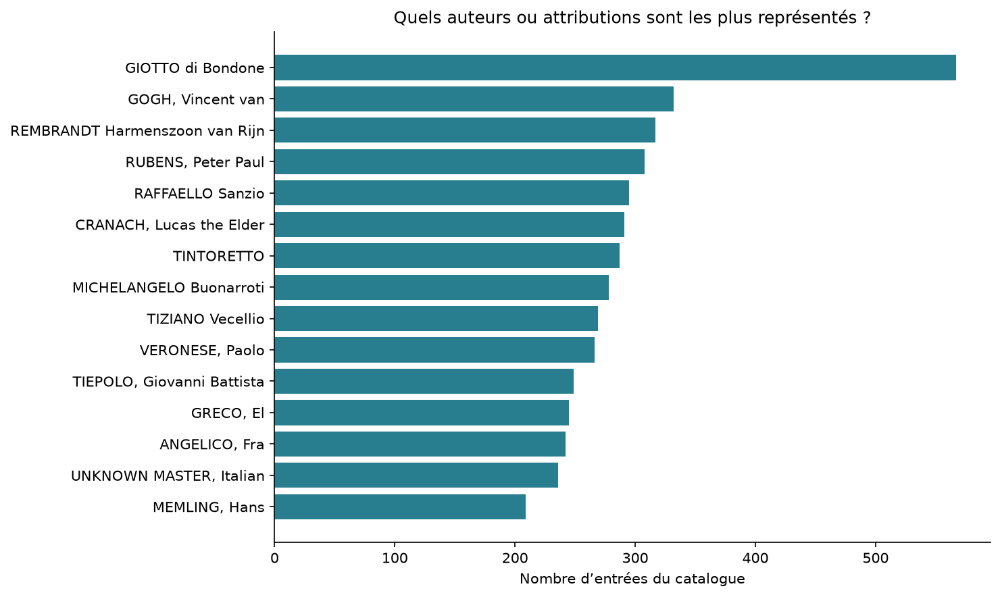

Les fréquences comptent des entrées, y compris détails et variantes. Une attribution n’est pas toujours une personne unique.

### La représentation des auteurs est-elle équilibrée ?

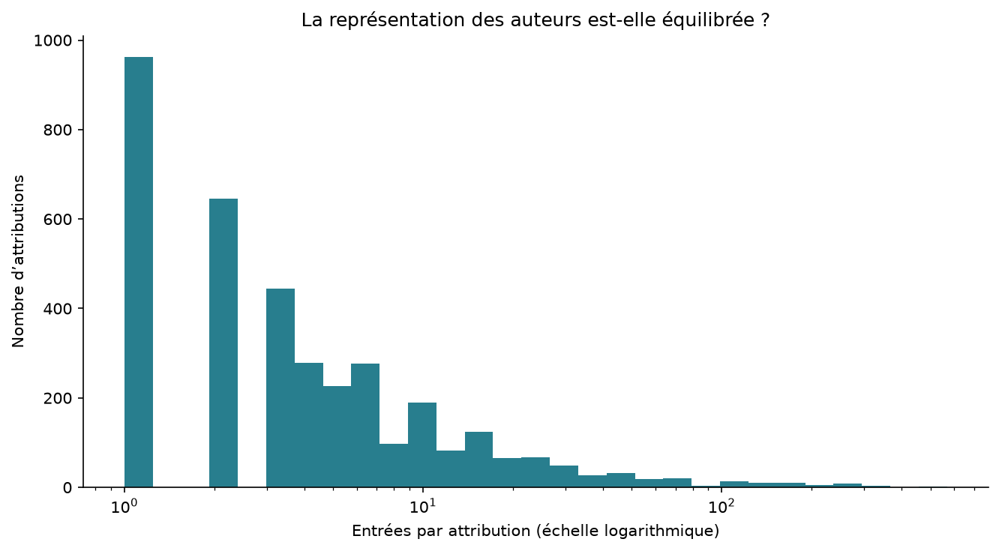

Les auteurs peu représentés et les attributions très fréquentes ne contribuent pas également au corpus.

### Quelles écoles artistiques dominent le catalogue ?

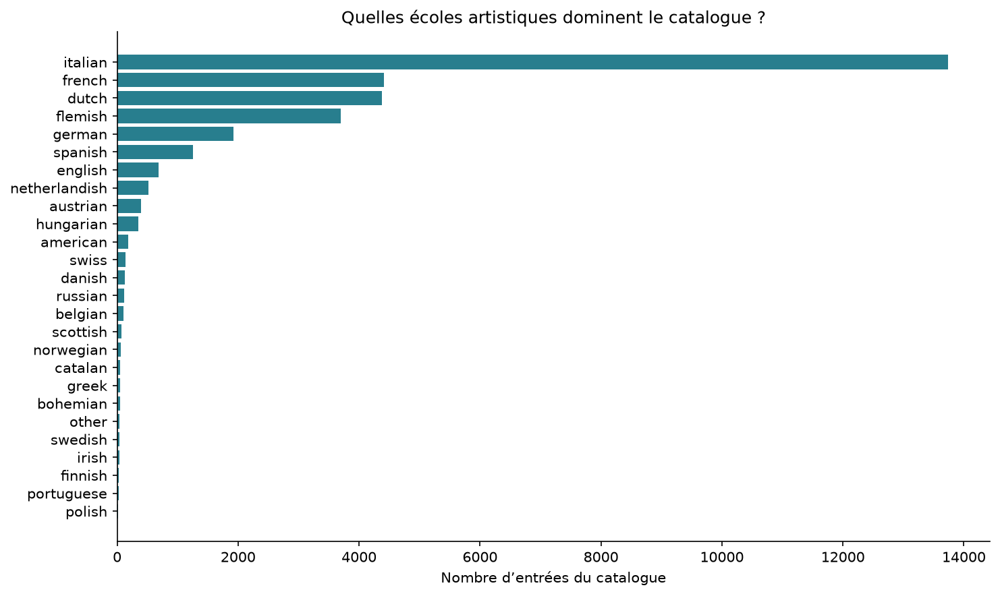

SCHOOL est une école du catalogue, sans équivalence automatique avec nationalité, pays ou mouvement artistique.

### Quels sujets sont les plus représentés ?

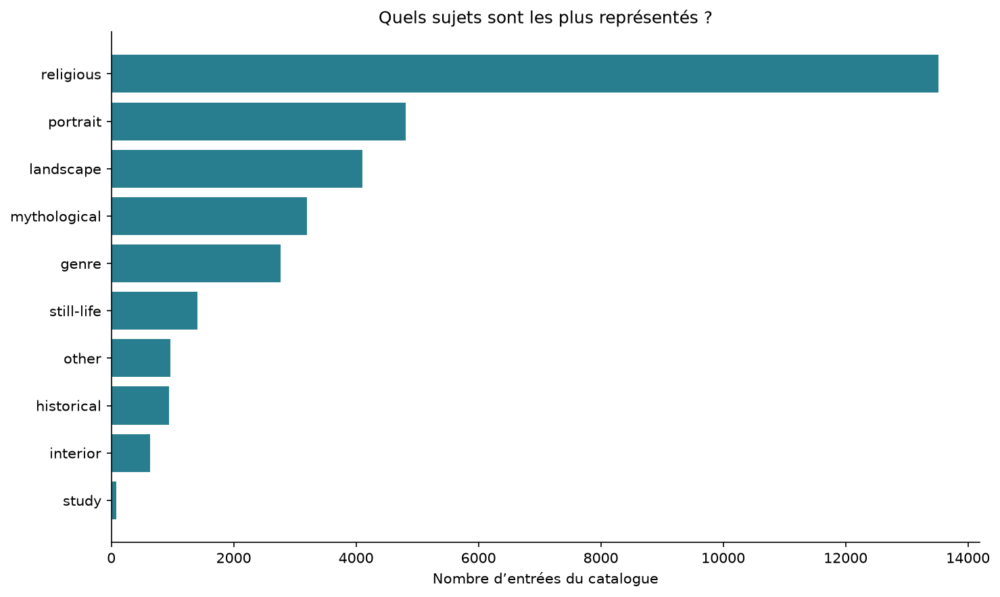

TYPE décrit les thèmes et ne permet pas de mesurer impressionnisme, cubisme ou expressionnisme.

### Quels lieux de conservation sont les plus renseignés ?

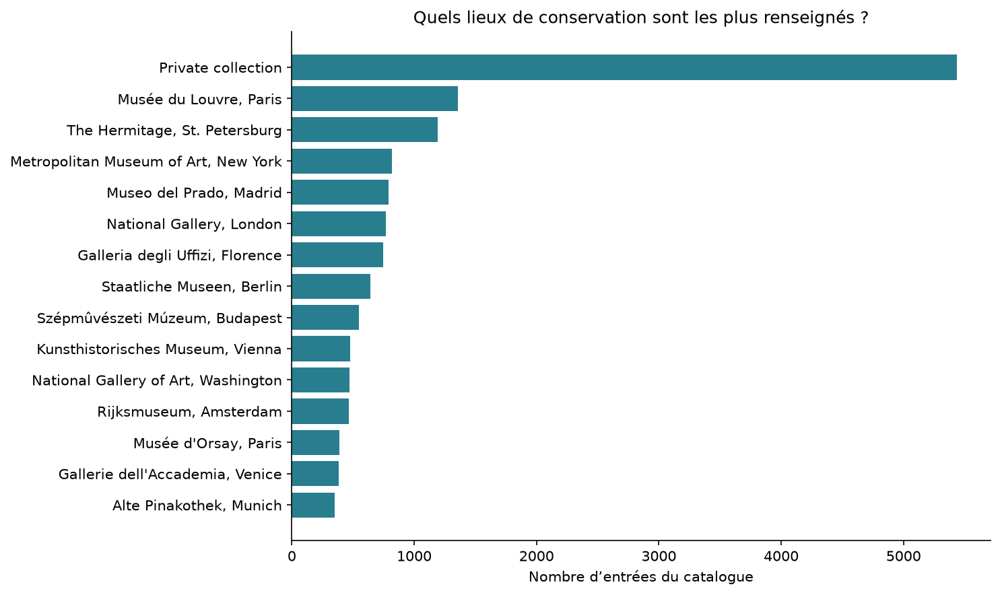

Le lieu de conservation ne renseigne ni le pays de création ni la nationalité de l’artiste.

In [26]:
from IPython.display import Image 

display(Markdown("### Taille du corpus"))
display(eda_tables["dataset_size"])

display(Markdown("### Principales attributions"))
display(eda_tables["artists"].head(20))

display(Markdown("### Écoles artistiques"))
display(eda_tables["schools"])

display(Markdown("### Sujets des peintures"))
display(eda_tables["themes"])

display(Markdown("### Principaux lieux de conservation"))
display(eda_tables["locations"].head(20))

show_eda_figures([
    "01_",
    "02_",
    "03_",
    "04_",
    "05_",
])

### Précision des datations

,date_kind,nombre
0,year,10435
1,range,9136
2,approximate_year,6702
3,missing,3888
4,decade,1577
5,unparsed,421
6,after,130
7,century,84
8,before,65


### Répartition par siècle représentatif

,century_representative,nombre
0,3,8
1,4,2
2,5,1
3,8,7
4,9,6
5,10,5
6,11,39
7,12,45
8,13,337
9,14,1897


### Quelle précision chronologique est disponible ?

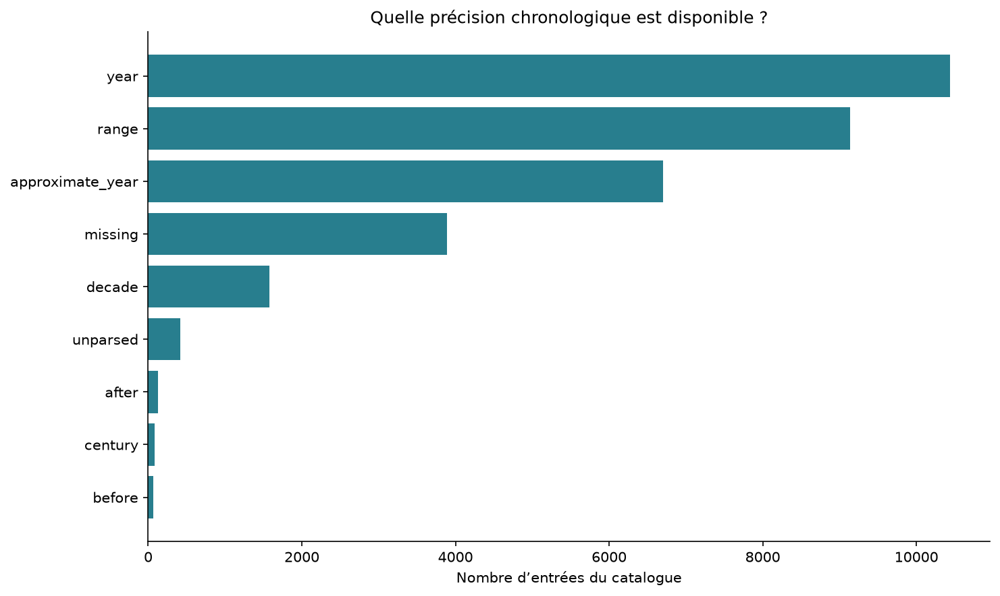

Les bornes, siècles, absences et datations complexes imposent des analyses et dénominateurs distincts.

### Comment les peintures se répartissent-elles dans le temps ?

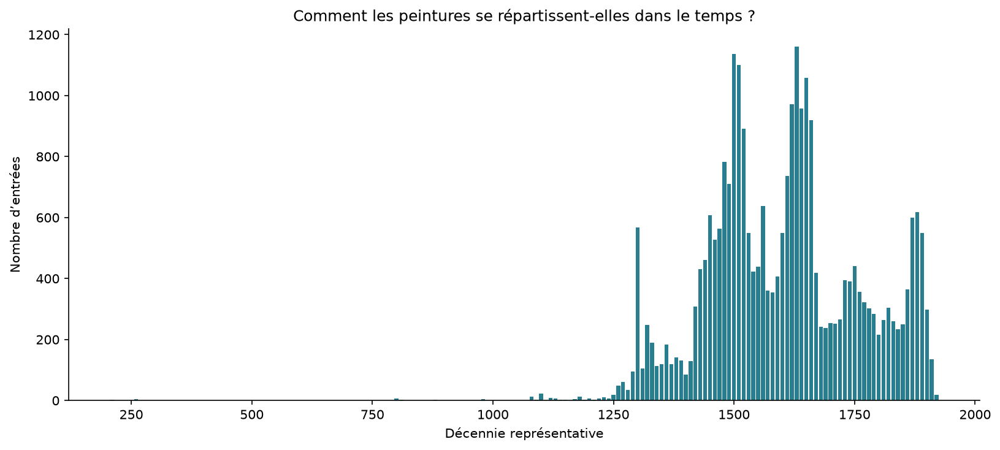

Analyse sur 27837 entrées : milieu des intervalles de 50 ans maximum, années et décennies. Ce sont des dates représentatives, pas des dates exactes.

### Comment les peintures se répartissent-elles dans le temps ?

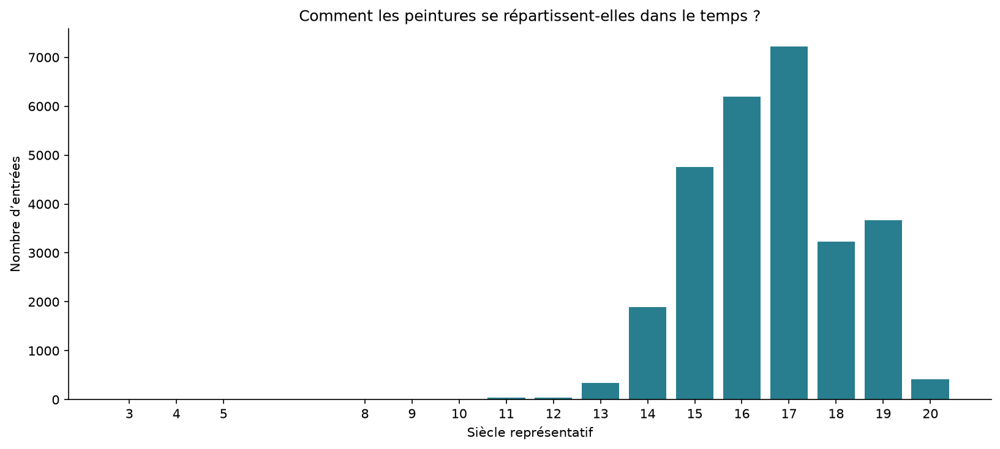

Analyse sur 27837 entrées : milieu des intervalles de 50 ans maximum, années et décennies. Ce sont des dates représentatives, pas des dates exactes.

### Quelles années sont renseignées sans approximation ni incertitude ?

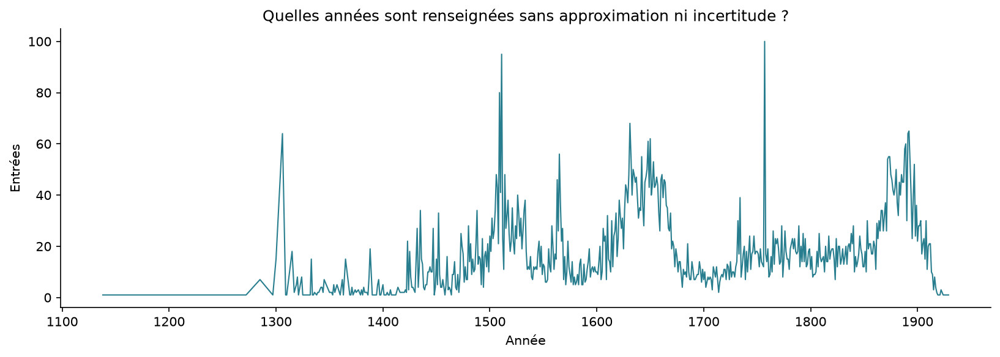

Le sous-ensemble à année simple non incertaine sert de complément et peut différer du corpus complet.

In [27]:
display(Markdown("### Précision des datations"))
display(eda_tables["date_coverage"])

display(Markdown("### Répartition par siècle représentatif"))
display(eda_tables["08_centuries"])

show_eda_figures([
    "06_",
    "07_",
    "08_",
    "09_",
])

### Familles de médiums

,famille,nombre
0,Huile,22613
1,Fresque,4642
2,Tempera,2928
3,Autre / non identifié,1543
4,Mixte (médiums reconnus),392
5,Pastel,168
6,Photo (à examiner),65
7,Aquarelle,62
8,Gouache,19
9,Encaustique,5


### Couverture de l’extraction des dimensions

,statut,nombre
0,pair_assumed_height_width,22220
1,not_reported_or_unparsed,9358
2,detail_frame_or_multiple_object,570
3,diameter,232
4,multiple_pairs,57
5,missing_technique,1


### Orientations supposées des œuvres

,orientation,nombre
0,Portrait supposé,12256
1,Paysage supposé,9371
2,Quasi carré (±5 %),593


### Dimensions à examiner

,source_record,TITLE,TECHNIQUE_raw,height_assumed_cm,width_assumed_cm,ratio_width_height_assumed
3241,6983,St John on Patmos,"Tempera on panel, 21 x 269 cm (entire predella)",21.0,269.0,12.809524
3242,6984,St Augustine in His Cell,"Tempera on panel, 21 x 269 cm (entire predella)",21.0,269.0,12.809524
3243,6985,Annunciation,"Tempera on panel, 21 x 269 cm (entire predella)",21.0,269.0,12.809524
3244,6986,St Jerome in Penitence,"Tempera on panel, 21 x 269 cm (entire predella)",21.0,269.0,12.809524
3245,6987,Miracle of St Eligius,"Tempera on panel, 21 x 269 cm (entire predella)",21.0,269.0,12.809524
3535,7416,The Quarrel between Ajax and Odysseus,"Oil on copper, 30 x 408 cm",30.0,408.0,13.600000
4300,8508,The Beguiling of Merlin,"Oil on canvas, 186 x 11 cm",186.0,11.0,0.059140
5182,9710,The Dream of Saint Catherine of Alexandria,"Oil on canvas, 139 x 11 cm",139.0,11.0,0.079137
6331,11344,Madonna and Child,"Panel, 2238 x 135 cm",2238.0,135.0,0.060322
6669,11782,The Adoration of the Magi,"Oil on panel, 88, 4 x 72,5 cm",4.0,72.5,18.125000


### Quels médiums peut-on identifier dans TECHNIQUE ?

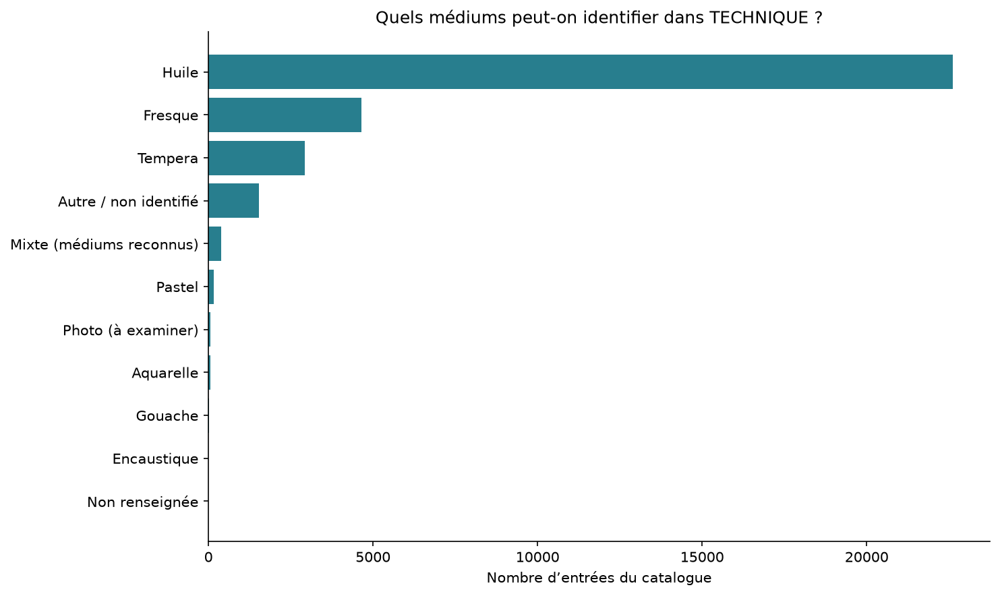

Classification indicative par mots-clés, pas une taxonomie artistique exhaustive. Les médiums inconnus restent distincts.

### Quelles tailles et proportions physiques peut-on extraire ?

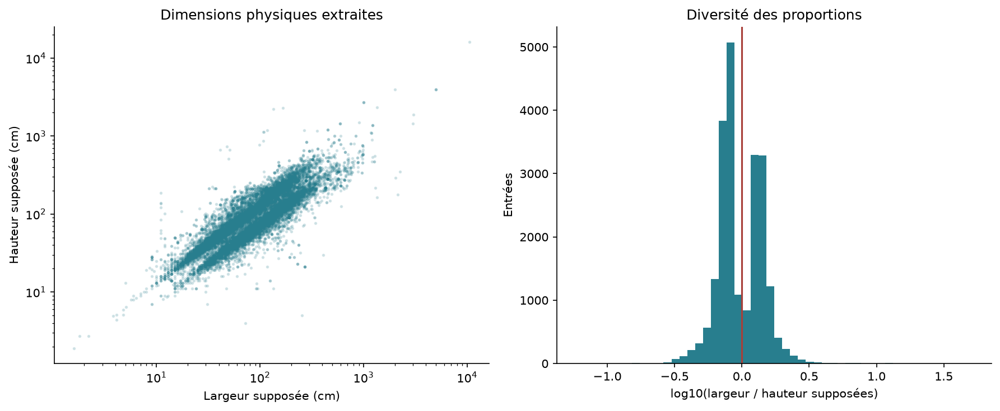

22220 paires explicites extraites. Hypothèse hauteur puis largeur. Les dimensions physiques ne sont ni les résolutions ni les ratios mesurés des images téléchargées.

In [28]:
display(Markdown("### Familles de médiums"))
display(eda_tables["technique_families"])

display(Markdown("### Couverture de l’extraction des dimensions"))
display(eda_tables["dimension_coverage"])

display(Markdown("### Orientations supposées des œuvres"))
display(eda_tables["orientations"])

display(Markdown("### Dimensions à examiner"))
display(eda_tables["dimension_review"].head(20))

show_eda_figures([
    "12_",
    "13_",
])

### Valeurs manquantes

,variable,nombre,pourcentage
0,AUTHOR,0,0.000000
1,BORN-DIED,0,0.000000
2,TITLE,0,0.000000
3,DATE,3888,11.985942
4,TECHNIQUE,1,0.003083
5,LOCATION,4,0.012331
6,URL,0,0.000000
7,FORM,0,0.000000
8,TYPE,0,0.000000
9,SCHOOL,0,0.000000


### Disponibilité des dates et dimensions par école

,SCHOOL,nombre,dimension_pct,chronology_pct
0,italian,13743,50.891363,89.834825
1,french,4410,87.687075,88.321995
2,dutch,4375,85.942857,74.034286
3,flemish,3697,74.952664,77.116581
4,german,1923,72.386895,91.991680
5,spanish,1250,82.160000,88.400000
6,english,681,90.014684,79.295154
7,netherlandish,514,47.276265,93.579767
8,austrian,391,76.726343,85.421995
9,hungarian,345,89.565217,92.463768


### Quelles métadonnées manquent ?

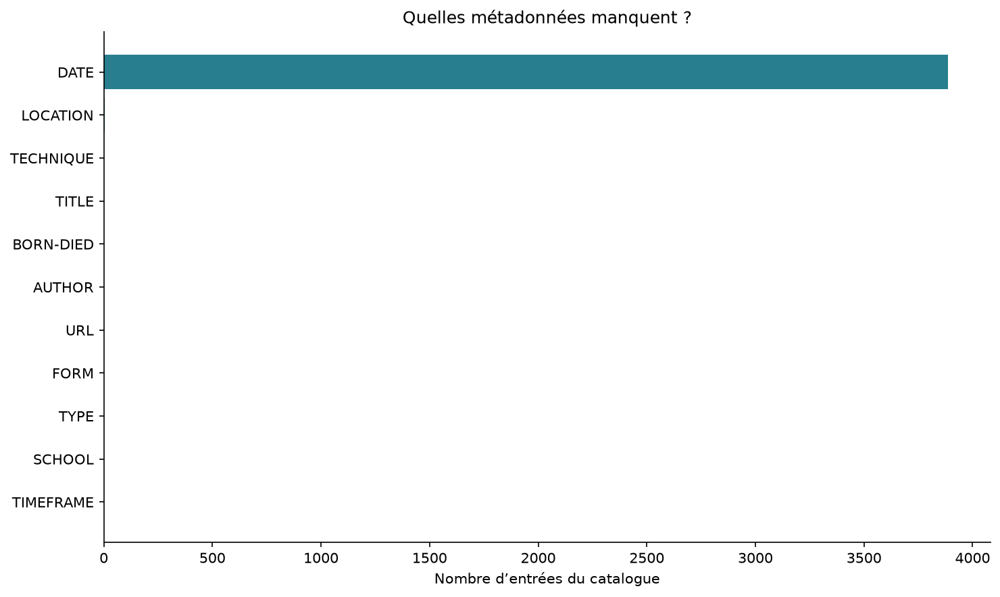

Les entrées sans date restent potentiellement utiles pour l’entraînement sur les images. Aucune imputation par TIMEFRAME n’est appliquée.

### Les données manquantes apparaissent-elles ensemble ?

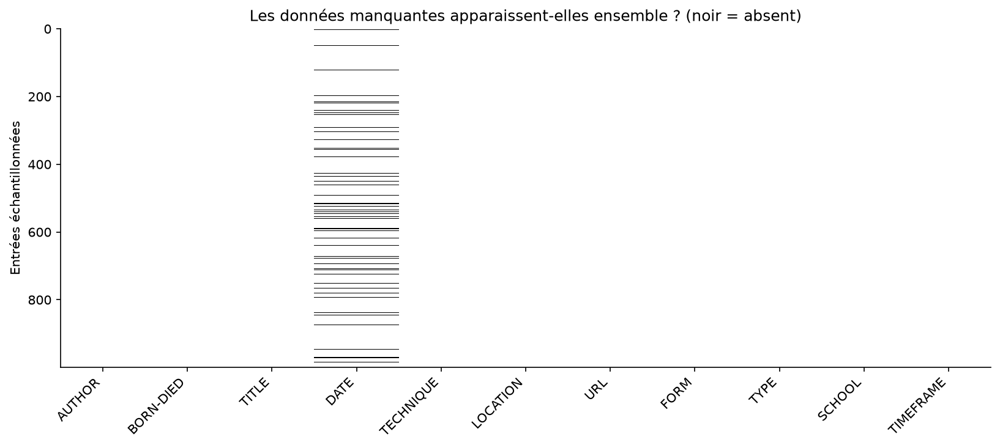

Échantillon reproductible de 1000 entrées, limité aux 11 métadonnées d’origine.

In [29]:
display(Markdown("### Valeurs manquantes"))
display(eda_tables["missing_values"])

display(Markdown("### Disponibilité des dates et dimensions par école"))
display(eda_tables["coverage_by_school"])

show_eda_figures([
    "10_",
    "11_",
])

### Associations catégorielles : V de Cramér

,relation,n,cramers_v_grouped
0,SCHOOL / TYPE,32438,0.203897
1,century_representative / TYPE,27837,0.244100
2,AUTHOR / century_representative,27837,0.239196


### Dimensions et époque : corrélations de Spearman

,variable,year_representative,height_assumed_cm,width_assumed_cm,ratio_width_height_assumed,area_assumed_cm2
0,year_representative,1.000000,-0.071081,0.046438,0.230124,-0.011179
1,height_assumed_cm,-0.071081,1.000000,0.852851,-0.174992,0.961451
2,width_assumed_cm,0.046438,0.852851,1.000000,0.304608,0.961938
3,ratio_width_height_assumed,0.230124,-0.174992,0.304608,1.000000,0.067690
4,area_assumed_cm2,-0.011179,0.961451,0.961938,0.067690,1.000000


### Les thèmes varient-ils selon l’école artistique ?

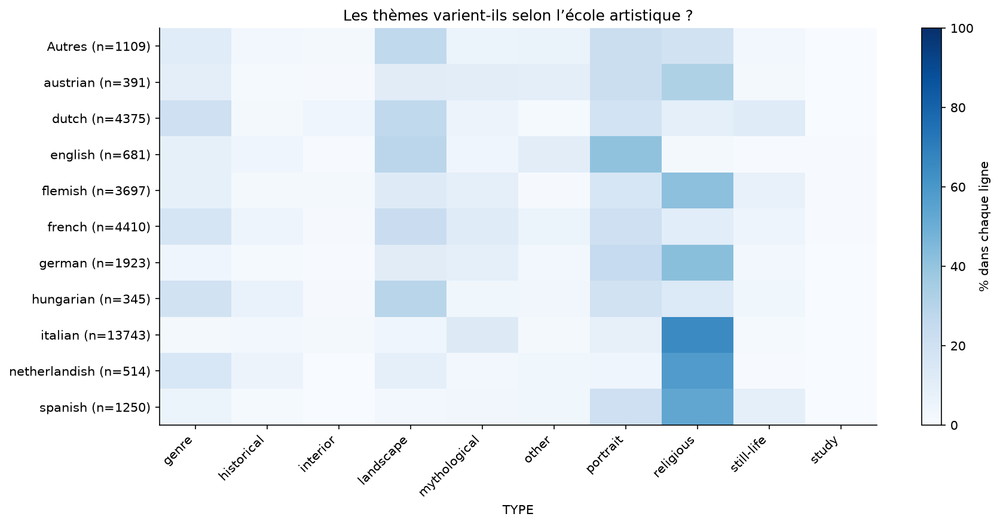

32438 entrées utilisables. Pourcentages par ligne. Les catégories hors des principales retenues sont regroupées dans « Autres », lorsqu’il y en a. Association descriptive, sans causalité.

### Les thèmes varient-ils selon le siècle représentatif ?

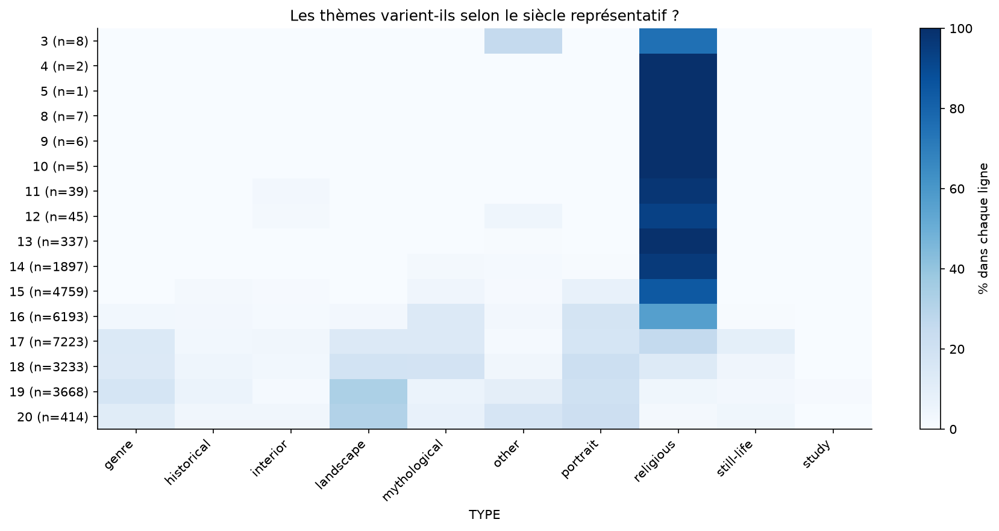

27837 entrées utilisables. Pourcentages par ligne. Les catégories hors des principales retenues sont regroupées dans « Autres », lorsqu’il y en a. Association descriptive, sans causalité.

### Quelle est la répartition temporelle des principales attributions ?

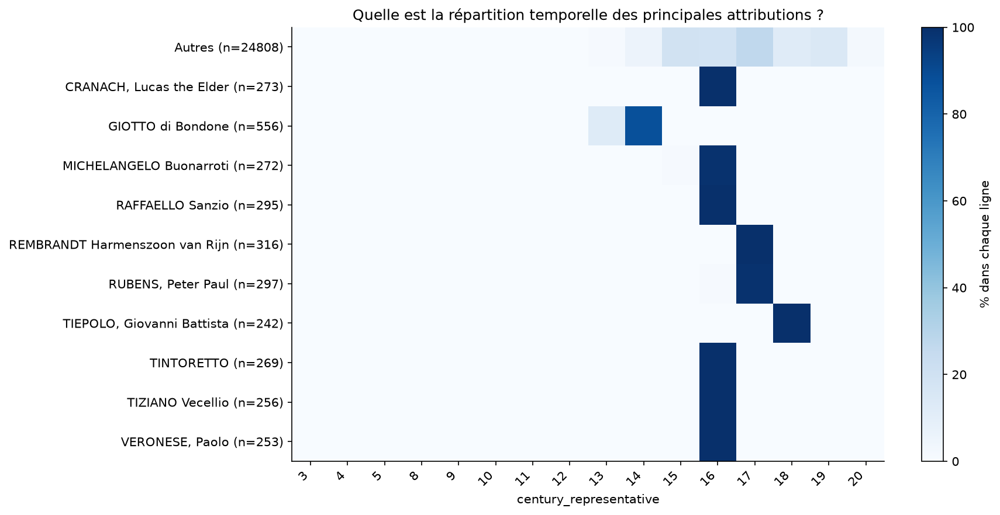

27837 entrées utilisables. Pourcentages par ligne. Les catégories hors des principales retenues sont regroupées dans « Autres », lorsqu’il y en a. Association descriptive, sans causalité.

### Les dimensions documentées varient-elles avec l’époque ?

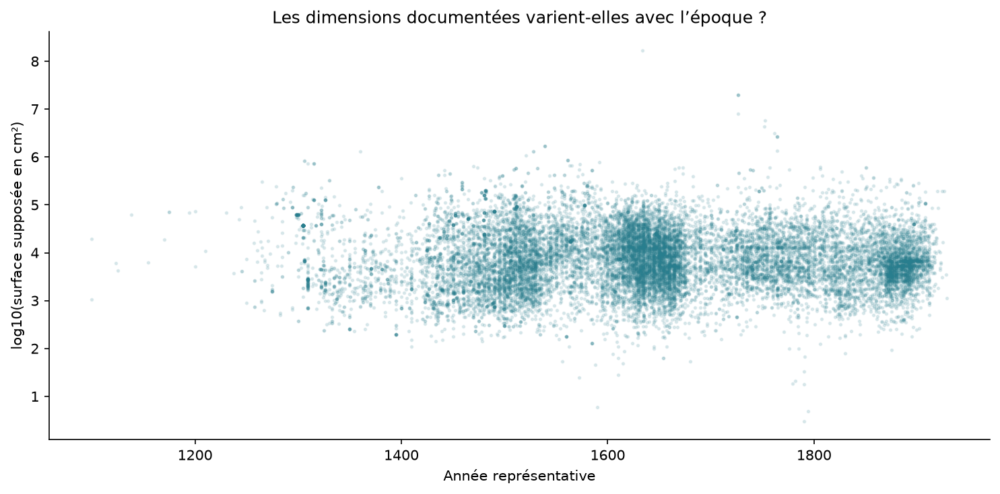

18590 entrées datables avec dimensions. Corrélations de Spearman descriptives, sensibles au corpus sélectionné et aux approximations.

In [ ]:
display(Markdown("### Associations catégorielles : V de Cramér"))
display(eda_tables["categorical_associations"])

display(Markdown("### Dimensions et époque : corrélations de Spearman"))
display(eda_tables["dimension_date_spearman"])

show_eda_figures([
    "14_",
    "15_",
    "16_",
    "17_",
])

In [30]:
display(
    Markdown(
        eda["report_path"].read_text(encoding="utf-8")
    )
)

# EDA du catalogue des peintures — Étape 7

## Périmètre et source

Analyse du CSV fourni par l’école :
- 52,867 entrées dans le catalogue brut ;
- 32,438 peintures, soit 61.36 % ;
- 32,438 entrées dans le catalogue nettoyé.

Les comptages portent sur les entrées du catalogue, pas sur des œuvres
uniques ou des images utilisables.

Sources locales : data/raw/art_catalog.csv et data/interim/paintings.csv.
Aucune source externe ni analyse des pixels n’est utilisée.

## Artistes et déséquilibre

Le corpus contient 3,663 libellés d’auteurs ou d’attributions
distincts. L’attribution la plus représentée est GIOTTO di Bondone
avec 567 entrées.

Les dix premières représentent 9.90 % du corpus.
La médiane est de 3.0 entrées par attribution,
contre une moyenne de 8.86.

Les fréquences peuvent être amplifiées par des détails et variantes.
Les libellés d’auteurs ne constituent pas une liste certaine de personnes
uniques.

Conséquence pour le GAN : les groupes les plus fréquents contribueront
davantage aux exemples d’entraînement. Le futur dédoublonnage des images
et une partition par œuvre ou groupe de variantes réduiront la fuite
entre entraînement et évaluation.

## Thèmes, écoles et géographie

Le catalogue comprend 10 catégories de sujets.
Le sujet dominant est religious :
13,517 entrées, soit 41.67 %.

Il comprend 26 écoles artistiques.
L’école dominante est italian :
13,743 entrées, soit 42.37 %.

Le catalogue ne possède pas de champ explicite de mouvement artistique.
TYPE est le sujet et SCHOOL l’école renseignée : on ne peut pas établir
une répartition fiable entre impressionnisme, cubisme et expressionnisme
à partir de ces seules colonnes. Aucun mouvement n’est inféré des dates.

La nationalité et le pays de création ne sont pas renseignés dans des
champs structurés. SCHOOL fournit un contexte culturel et géographique
indicatif, sans équivalence avec une nationalité.

LOCATION décrit le lieu de conservation, parfois une collection privée.
BORN-DIED contient des lieux biographiques qui ne suffisent pas à
déterminer une nationalité. Les écoles et lieux sont analysés séparément.

## Chronologie et incertitude

27,837 entrées, soit 85.82 %,
disposent d’une année représentative selon la règle définie.

Pour une plage de 50 ans maximum, on utilise son milieu.
Pour une décennie, on utilise le milieu de ses bornes.
Ce choix est descriptif et ne transforme pas la datation en date exacte.

Les années approximatives gardent leur indicateur dans le catalogue.
Les dates absentes, complexes, before/after et siècles larges ne sont
pas inclus dans cette distribution.

Une analyse complémentaire présente les années simples sans incertitude.
Le numéro du siècle représentatif le plus fréquent est :
17.

Des intervalles peuvent traverser des frontières de décennies ou de
siècles. L’affectation par milieu réduit cette information.
Les tableaux de bornes restent disponibles.

TIMEFRAME n’est ni substitué à DATE ni utilisé pour imputer les dates
manquantes.

## Techniques, dimensions et preprocessing

La famille Huile regroupe 22,613 entrées,
soit 69.71 %.

Les familles de médiums sont dérivées par mots-clés explicites.
Les mélanges reconnus, médiums inconnus et techniques manquantes
restent séparés. Cette classification ne correspond pas à des styles
artistiques.

22,220 entrées, soit
68.50 %, comportent une paire de
dimensions physiques exploitable selon la règle conservatrice :
une paire, une unité commune cm/mm/m, sans détail, cadre ou objet
multiple identifié.

Les diamètres et les cas non interprétés sont conservés dans le bilan
de couverture.

L’ordre hauteur puis largeur est une hypothèse à vérifier, pas une
information garantie pour toutes les entrées.
La virgule est interprétée comme séparateur décimal dans les mesures.

- Médiane de hauteur supposée : 79.00 cm.
- Médiane de largeur supposée : 77.00 cm.
- Ratio médian largeur/hauteur supposées : 0.857.
- Formats portrait supposés : 12,256.
- Formats paysage supposés : 9,371.
- Formats quasi carrés, tolérance de 5 % : 593.

36 entrées aux dimensions ou proportions extrêmes
sont signalées pour examen, sans suppression automatique.

Les seuils de revue sont :
- une dimension inférieure à 1 cm ;
- une dimension supérieure à 2 000 cm ;
- un ratio largeur/hauteur inférieur à 0,1 ou supérieur à 10.

Une fresque très grande ou un panneau très allongé peut être légitime.

Les dimensions physiques ne donnent pas la résolution des fichiers.
Elles suggèrent des proportions variées. Le choix entre recadrage et
ajout de bordures devra être confirmé après visualisation et mesure
des images téléchargées.

Un redimensionnement carré sans préservation des proportions peut
déformer les œuvres.

## Valeurs manquantes et couverture

- Dates manquantes : 3888, soit 11.99 %.
- Techniques manquantes : 1.
- Localisations manquantes : 4.

Les dates non interprétées ne sont pas des champs absents :
elles contiennent une information conservée.

L’absence de dimensions dérivées peut simplement correspondre à un texte
non interprétable.

Le tableau de couverture par école permet de repérer la sélection
induite par la disponibilité des dates et dimensions.

La matrice de manque porte sur un échantillon fixe de
1000 entrées.

Ces métadonnées manquantes ne justifient pas l’exclusion d’une image valide
d’un GAN non conditionnel.

## Associations descriptives

Les tableaux école/thème, siècle représentatif/thème et
auteur/siècle représentatif sont présentés en effectifs et pourcentages
par ligne.

Les attributions fréquentes sont sélectionnées avant regroupement
des autres.

Dans ce catalogue, la part de sujets religieux vaut :
- école italian : 64.93 % ;
- école dutch : 9.19 %.

Cela décrit la sélection du catalogue, pas toute la production historique
de ces écoles.

Les matrices précisent le nombre d’entrées par ligne.
La table siècle/thème décrit les thèmes au sein de chaque siècle
représentatif.

Le V de Cramér décrit les tables regroupées.
Ses valeurs dépendent de ces regroupements.

Aucun code numérique arbitraire n’est attribué aux catégories pour
calculer une corrélation de Pearson.

Sur 18,590 entrées disposant de dimensions et
d’une date représentative, la corrélation de Spearman
année/surface supposée vaut -0.011.

Elle est descriptive : ni causalité ni test d’hypothèse.
Les approximations de dates, les détails et variantes, et la couverture
inégale limitent sa portée.

## Conclusions pour le projet

1. Le catalogue comprend de nombreuses entrées, mais le nombre final
   d’images exploitables reste inconnu.
2. Les biais d’attribution, d’école et de thème doivent être présentés
   avec les résultats du GAN.
3. Les datations nécessitent des indicateurs d’incertitude et des
   dénominateurs explicites.
4. Les dimensions physiques suggèrent un besoin de traitement des ratios,
   à confirmer sur les pixels.
5. Le scraping doit assurer la traçabilité source_record / URL / fichier
   et gérer les pages indisponibles.
6. Contrôler les images identiques et proches avant de constituer les jeux
   d’entraînement et d’évaluation.
7. Le prochain travail est le scraping. Cette EDA ne mesure ni couleurs,
   ni résolution, ni qualité visuelle.

## Reproduction et fichiers

Exécuter run_eda(PROJECT_ROOT) depuis les cellules du notebook.

Les tableaux et ce rapport sont enregistrés dans data/interim/eda/.
Les figures PNG sont enregistrées dans images/eda/.

paintings.csv et le CSV brut restent inchangés.

eda_metadata.csv contient les champs dérivés, reliés au catalogue
par source_record.

Les hypothèses d’extraction sont explicites dans le script.
Les figures ont chacune une question et une note d’interprétation
dans figures.json.


## Inspection de huit pages et des liens d’images

Nous vérifions la chaîne :

CSV → page HTML → lien d’image présent dans le HTML
→ fichier téléchargé et décodable.

L’échantillon est reproductible avec random_state=42.
Il ne garantit pas le succès sur toutes les pages du catalogue.

Les liens d’images sont recherchés dans :
- les liens a[href] ;
- les images img[src] et img[data-src] ;
- les métadonnées og:image et twitter:image.

Les liens relatifs sont résolus à partir de l’URL de la page.

La sélection privilégie un nom de fichier identique à celui de la page
et le répertoire /art/. Cette règle est une hypothèse à valider
sur les fichiers reçus.

Aucune URL d’image n’est fabriquée par remplacement de texte.

Les ambiguïtés et erreurs sont conservées dans le manifeste.
Seules huit pages sont testées et au maximum une image par page
est téléchargée.

Une image décodable n’est pas forcément la bonne œuvre :
une vérification visuelle reste nécessaire.

In [31]:
from IPython.display import (
    display,
    Markdown,
    Image,
)

PROJECT_ROOT = next(
    (
        path
        for path in [
            Path.cwd(),
            *Path.cwd().parents,
        ]
        if (
            path / "data/raw/art_catalog.csv"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Impossible de trouver la racine du projet"
    )

SCRIPT = (
    PROJECT_ROOT
    / "src/scraping/inspect_links.py"
)

if not SCRIPT.exists():
    raise FileNotFoundError(
        f"Placer inspect_links.py ici : {SCRIPT}"
    )

scraping_module = runpy.run_path(
    str(SCRIPT)
)

scraping_test = scraping_module[
    "inspect_sample"
](
    PROJECT_ROOT,
    n_pages=8,
    delay=1.5,
)

16677 downloaded_verified
41157 downloaded_verified
44916 downloaded_verified
36553 downloaded_verified
5727 downloaded_verified
30618 downloaded_verified
14511 downloaded_verified
11851 downloaded_verified


In [32]:
display(
    scraping_test[[
        "source_record",
        "TITLE",
        "page_http_status",
        "candidate_count",
        "image_url",
        "width_px",
        "height_px",
        "status",
        "error",
    ]]
)

display(
    scraping_test["status"]
    .value_counts()
    .rename("nombre")
    .to_frame()
)

candidates = pd.read_csv(
    PROJECT_ROOT
    / "data/interim/scraping_test/image_candidates.csv"
)

display(candidates)

,source_record,TITLE,page_http_status,candidate_count,image_url,width_px,height_px,status,error
0,16677,Still-Life,200,1,https://www.wga.hu/art/f/flegel/stil_oys.jpg,1400,881,downloaded_verified,
1,41157,Griffoni Polyptych: St George,200,1,https://www.wga.hu/art/r/roberti/griffoni/grif...,650,1670,downloaded_verified,
2,44916,River landscape,200,1,https://www.wga.hu/art/s/stalbemt/river_la.jpg,1096,881,downloaded_verified,
3,36553,Virgin and Child with a Swallow,200,1,https://www.wga.hu/art/p/pesellin/madonnaf.jpg,651,1000,downloaded_verified,
4,5727,Still-Life with Lobster and Fruit,200,1,https://www.wga.hu/art/b/beyeren/still_lo.jpg,1065,1300,downloaded_verified,
5,30618,Tommaso Portinari and his Wife,200,1,https://www.wga.hu/art/m/memling/1early1/04nop...,1160,750,downloaded_verified,
6,14511,The Sibyl,200,1,https://www.wga.hu/art/d/drost/b_sibyl.jpg,1117,1400,downloaded_verified,
7,11851,Portrait of Adolphe Marlet,200,1,https://www.wga.hu/art/c/courbet/2/courb217.jpg,678,850,downloaded_verified,


,nombre
status,
downloaded_verified,8


,source_record,image_url,origin,score
0,16677,https://www.wga.hu/art/f/flegel/stil_oys.jpg,a_href,150
1,41157,https://www.wga.hu/art/r/roberti/griffoni/grif...,a_href,150
2,44916,https://www.wga.hu/art/s/stalbemt/river_la.jpg,a_href,150
3,36553,https://www.wga.hu/art/p/pesellin/madonnaf.jpg,a_href,150
4,5727,https://www.wga.hu/art/b/beyeren/still_lo.jpg,a_href,150
5,30618,https://www.wga.hu/art/m/memling/1early1/04nop...,a_href,150
6,14511,https://www.wga.hu/art/d/drost/b_sibyl.jpg,a_href,150
7,11851,https://www.wga.hu/art/c/courbet/2/courb217.jpg,a_href,150


### Still-Life

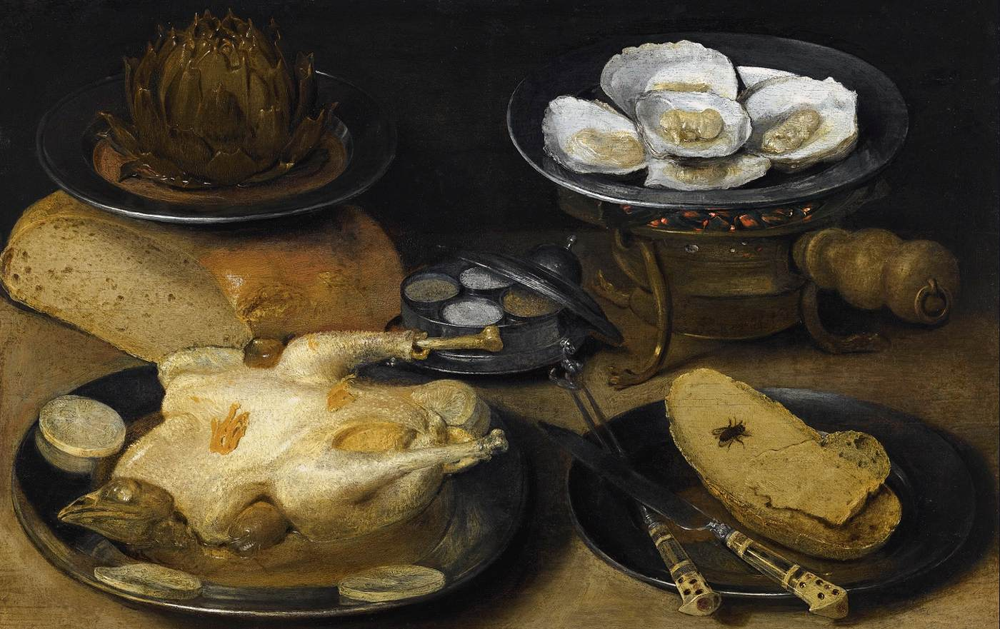

Page : https://www.wga.hu/html/f/flegel/stil_oys.html
Image : https://www.wga.hu/art/f/flegel/stil_oys.jpg
Pixels : 1400 x 881 | mode : RGB


### Griffoni Polyptych: St George

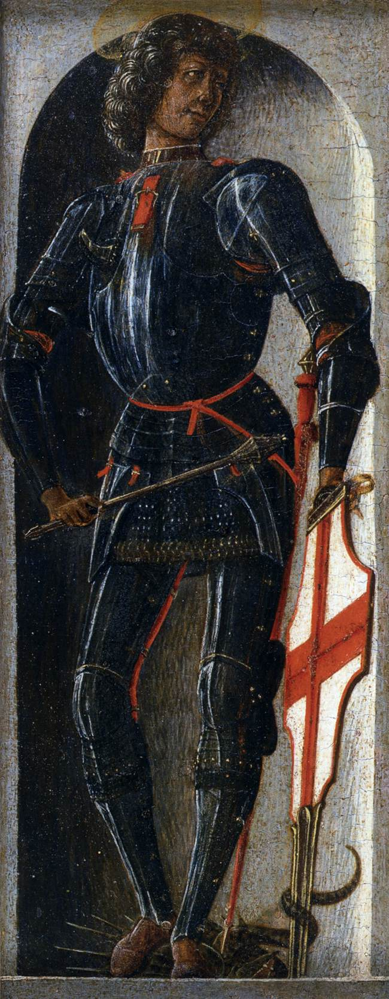

Page : https://www.wga.hu/html/r/roberti/griffoni/grif_05.html
Image : https://www.wga.hu/art/r/roberti/griffoni/grif_05.jpg
Pixels : 650 x 1670 | mode : RGB


### River landscape

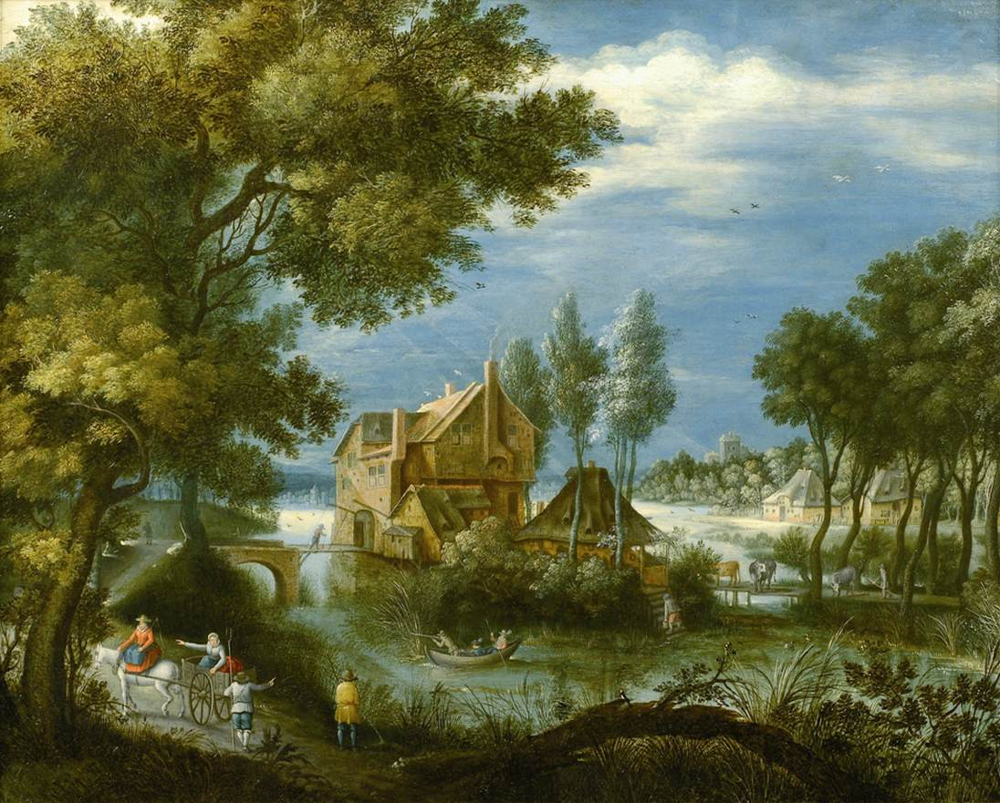

Page : https://www.wga.hu/html/s/stalbemt/river_la.html
Image : https://www.wga.hu/art/s/stalbemt/river_la.jpg
Pixels : 1096 x 881 | mode : RGB


### Virgin and Child with a Swallow

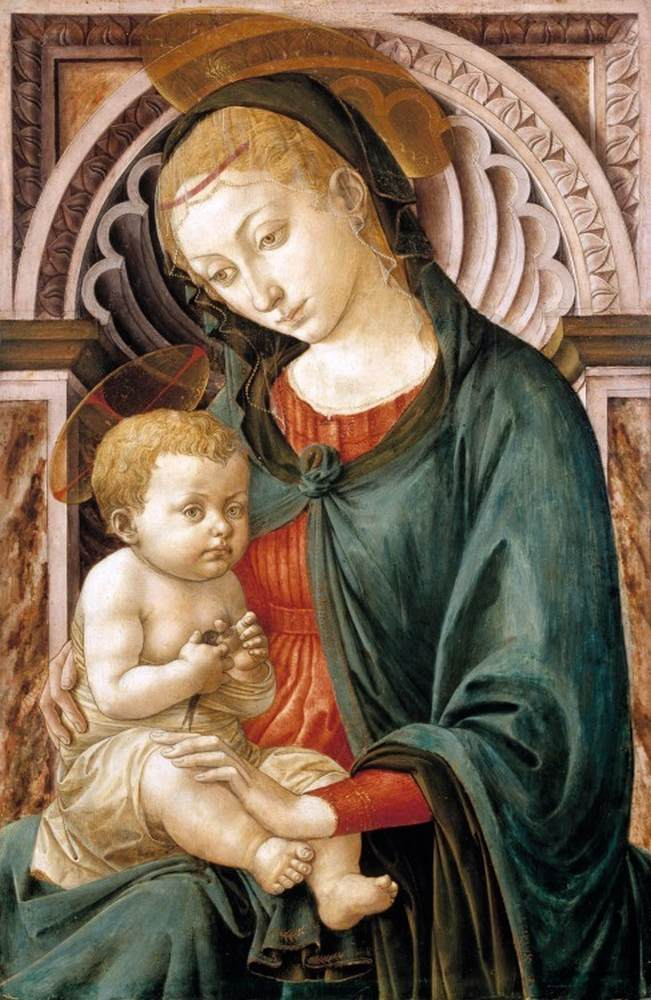

Page : https://www.wga.hu/html/p/pesellin/madonnaf.html
Image : https://www.wga.hu/art/p/pesellin/madonnaf.jpg
Pixels : 651 x 1000 | mode : RGB


### Still-Life with Lobster and Fruit

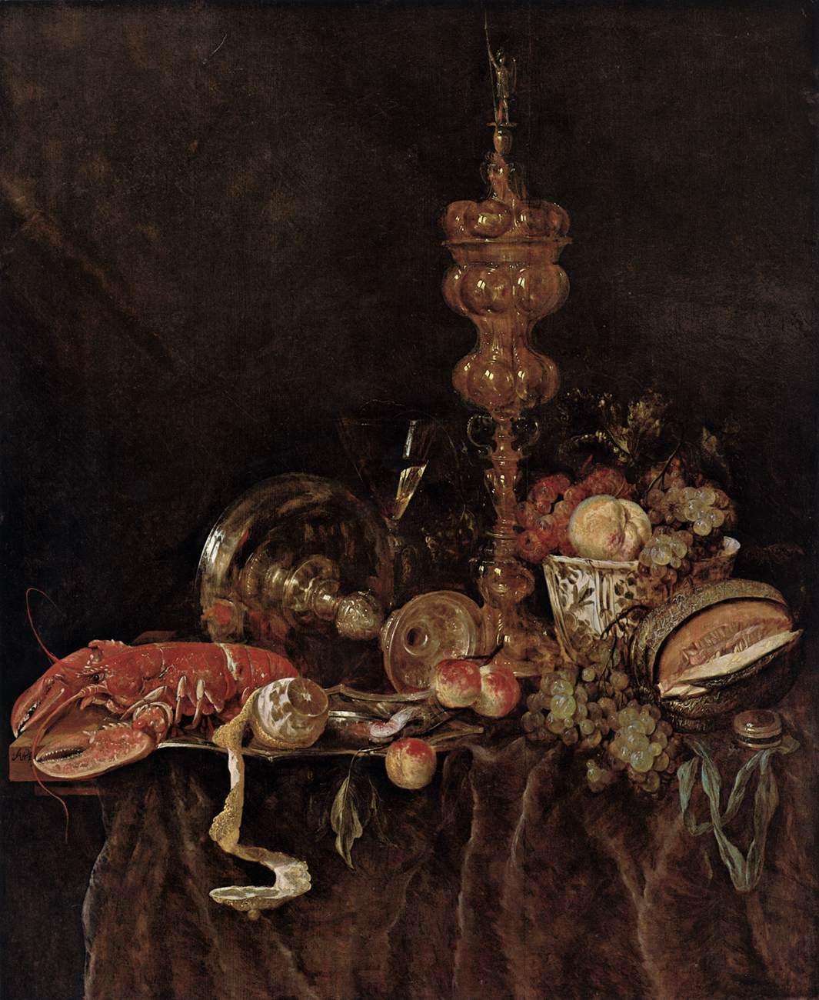

Page : https://www.wga.hu/html/b/beyeren/still_lo.html
Image : https://www.wga.hu/art/b/beyeren/still_lo.jpg
Pixels : 1065 x 1300 | mode : RGB


### Tommaso Portinari and his Wife

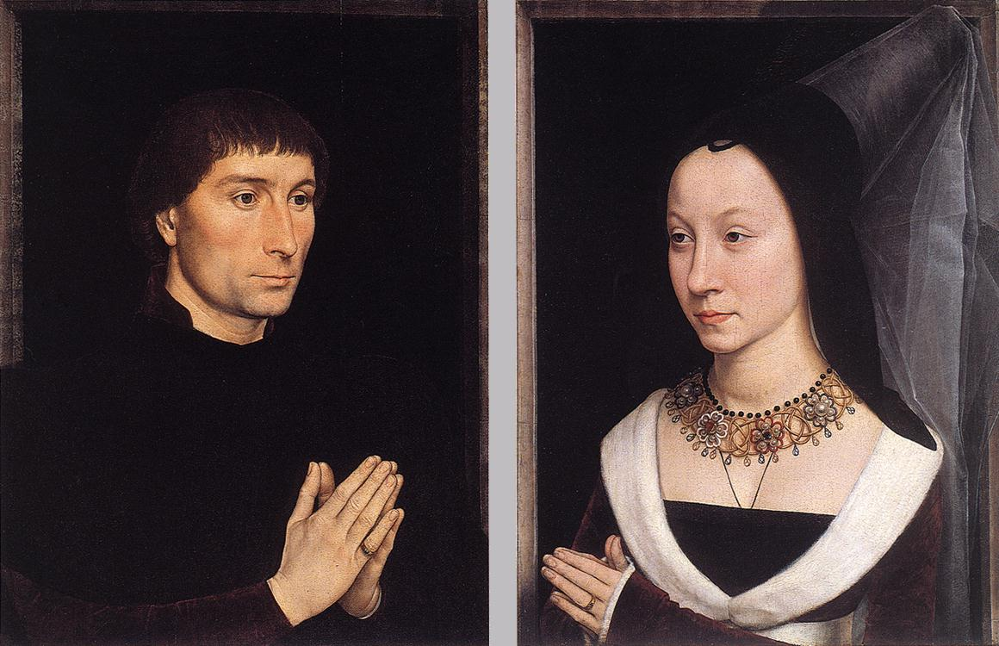

Page : https://www.wga.hu/html/m/memling/1early1/04noport.html
Image : https://www.wga.hu/art/m/memling/1early1/04noport.jpg
Pixels : 1160 x 750 | mode : RGB


### The Sibyl

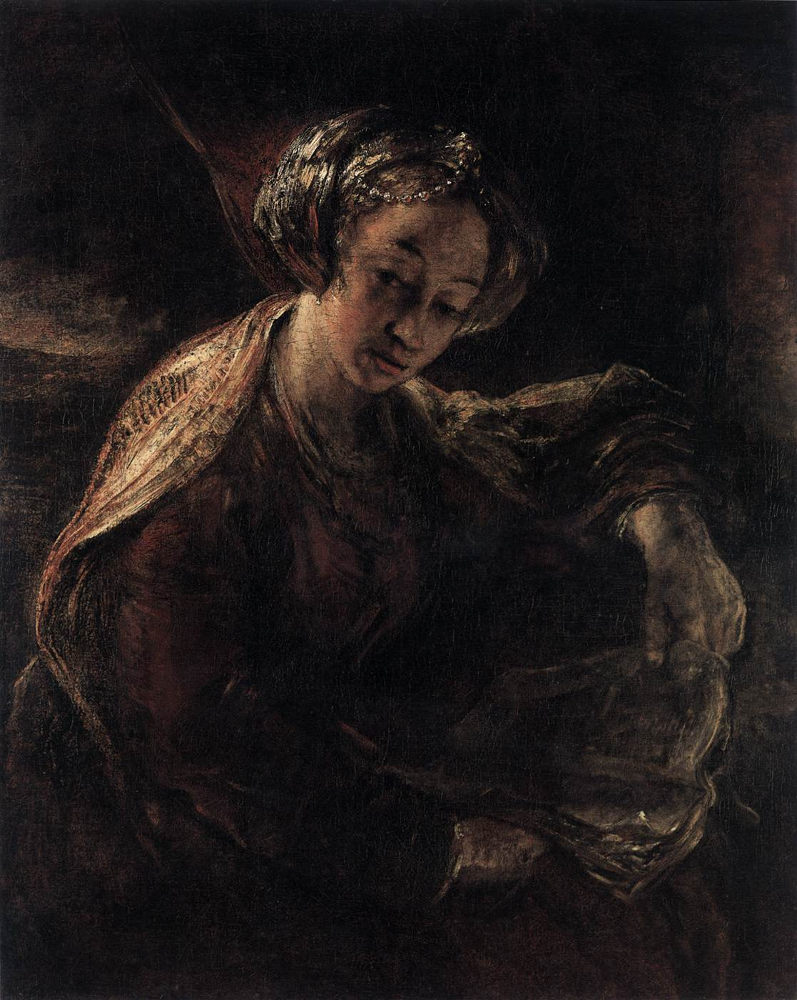

Page : https://www.wga.hu/html/d/drost/b_sibyl.html
Image : https://www.wga.hu/art/d/drost/b_sibyl.jpg
Pixels : 1117 x 1400 | mode : RGB


### Portrait of Adolphe Marlet

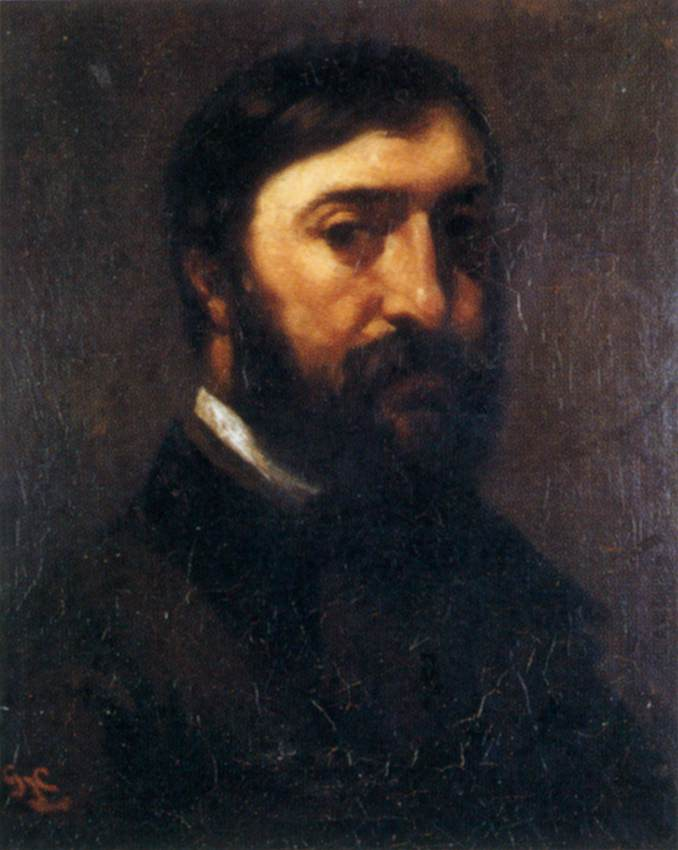

Page : https://www.wga.hu/html/c/courbet/2/courb217.html
Image : https://www.wga.hu/art/c/courbet/2/courb217.jpg
Pixels : 678 x 850 | mode : RGB


In [33]:
success = scraping_test[
    scraping_test["status"].isin([
        "downloaded_verified",
        "downloaded_small_review",
    ])
]

for _, row in success.iterrows():
    display(
        Markdown(
            "### " + str(row["TITLE"])
        )
    )

    display(
        Image(
            filename=str(
                PROJECT_ROOT / row["image_path"]
            ),
            width=500,
        )
    )

    print("Page :", row["page_url"])
    print("Image :", row["image_url"])

    print(
        "Pixels :",
        row["width_px"],
        "x",
        row["height_px"],
        "| mode :",
        row["image_mode"],
    )

if success.empty:
    print(
        "Aucune image validée. Examiner les erreurs "
        "avant le scraping complet."
    )

## Téléchargement du corpus

Le téléchargement est exécuté par le script indépendant
src/scraping/download_images.py.

Le scraper réutilise l’extraction des liens validée à l’étape 8.

Il gère :
- les requêtes HTTP et les timeouts ;
- les tentatives limitées sur les erreurs temporaires ;
- les pages et images introuvables ;
- les liens absents ou ambigus ;
- la vérification des images téléchargées ;
- les noms de fichiers uniques ;
- les logs et la reprise après interruption.

La progression est enregistrée après chaque entrée dans SQLite.
Un manifeste CSV est exporté tous les 100 traitements et à la sortie.

Les images originales restent sans redimensionnement ni normalisation.
Les petites images sont conservées avec un indicateur small_image.

Le contrôle complet du corpus et des doublons d’images sera effectué
à l’étape 10.

In [34]:
manifest_path = (
    PROJECT_ROOT
    / "data/interim/scraping/download_manifest.csv"
)

manifest = pd.read_csv(
    manifest_path,
    keep_default_na=False,
)

display(
    manifest["status"]
    .value_counts()
    .rename("nombre")
    .to_frame()
)

display(manifest.head(10))

summary_path = (
    PROJECT_ROOT
    / "data/interim/scraping/download_summary.json"
)

summary = json.loads(
    summary_path.read_text(encoding="utf-8")
)

print(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    )
)

# Quelques erreurs pour comprendre les échecs.
display(
    manifest.loc[
        manifest["status"].ne("downloaded"),
        [
            "source_record",
            "TITLE",
            "page_url",
            "status",
            "error",
        ],
    ].head(20)
)

,nombre
status,
downloaded,1000
temporary_error,157


,source_record,AUTHOR,TITLE,page_url,final_page_url,image_url,page_http_status,image_http_status,html_encoding,candidate_count,...,image_format,image_mode,width_px,height_px,image_sha256,small_image,status,error,retry_after_timestamp,updated_at
0,1,"AACHEN, Hans von",Venus and Adonis,https://www.wga.hu/html/a/aachen/adonis.html,https://www.wga.hu/html/a/aachen/adonis.html,https://www.wga.hu/art/a/aachen/adonis.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T07:59:02.509691+00:00
1,2,"AACHEN, Hans von",Allegory,https://www.wga.hu/html/a/aachen/allegory.html,https://www.wga.hu/html/a/aachen/allegory.html,https://www.wga.hu/art/a/aachen/allegory.jpg,200,200.0,iso-8859-1,1,...,JPEG,RGB,684.0,817.0,8214f90dd6f6fa352950a0aa3b96c7c0a5b8260348eb6e...,False,downloaded,,0,2026-10-07T07:59:03.826817+00:00
2,3,"AACHEN, Hans von","Allegory of Peace, Art and Abundance",https://www.wga.hu/html/a/aachen/allegorz.html,https://www.wga.hu/html/a/aachen/allegorz.html,https://www.wga.hu/art/a/aachen/allegorz.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:00:11.883697+00:00
3,4,"AACHEN, Hans von","Jupiter, Antiope and Cupid",https://www.wga.hu/html/a/aachen/antiope.html,https://www.wga.hu/html/a/aachen/antiope.html,https://www.wga.hu/art/a/aachen/antiope.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:01:19.301567+00:00
4,5,"AACHEN, Hans von","Pallas Athena, Venus and Juno",https://www.wga.hu/html/a/aachen/athena.html,https://www.wga.hu/html/a/aachen/athena.html,https://www.wga.hu/art/a/aachen/athena.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:02:26.695209+00:00
5,6,"AACHEN, Hans von","Bacchus, Ceres and Cupid",https://www.wga.hu/html/a/aachen/bacchus.html,https://www.wga.hu/html/a/aachen/bacchus.html,https://www.wga.hu/art/a/aachen/bacchus.jpg,200,200.0,iso-8859-1,1,...,JPEG,RGB,1173.0,1700.0,f940388db599022f1c28444e182171c8e1acaa5152251e...,False,downloaded,,0,2026-10-07T08:02:28.190489+00:00
6,7,"AACHEN, Hans von","Bacchus, Venus and Cupid",https://www.wga.hu/html/a/aachen/bacchus1.html,https://www.wga.hu/html/a/aachen/bacchus1.html,https://www.wga.hu/art/a/aachen/bacchus1.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:03:36.044014+00:00
7,8,"AACHEN, Hans von",David and Bathsheba,https://www.wga.hu/html/a/aachen/davidbat.html,https://www.wga.hu/html/a/aachen/davidbat.html,https://www.wga.hu/art/a/aachen/davidbat.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:04:43.396761+00:00
8,9,"AACHEN, Hans von",The Amazement of the Gods,https://www.wga.hu/html/a/aachen/gods.html,https://www.wga.hu/html/a/aachen/gods.html,https://www.wga.hu/art/a/aachen/gods.jpg,200,200.0,iso-8859-1,1,...,JPEG,RGB,1200.0,943.0,36434dd34fe09c557fe444b7411b9e91b66ba5481122cd...,False,downloaded,,0,2026-10-07T08:04:44.654168+00:00
9,10,"AACHEN, Hans von",Pan and Selene,https://www.wga.hu/html/a/aachen/gods1.html,https://www.wga.hu/html/a/aachen/gods1.html,https://www.wga.hu/art/a/aachen/gods1.jpg,200,,iso-8859-1,1,...,,,,,,False,temporary_error,TimeoutError: The read operation timed out,0,2026-10-07T08:05:52.722195+00:00


{
  "catalogue_entries": 32438,
  "tracked_entries": 1157,
  "untracked_entries": 31281,
  "status_counts": {
    "downloaded": 1000,
    "temporary_error": 157
  },
  "processed_this_run": 1057,
  "skipped_this_run": 2,
  "stop_reason": "target_reached",
  "updated_at": "2026-10-07T10:01:39.790972+00:00",
  "target_success": 1000,
  "images_toward_target": 1000
}


,source_record,TITLE,page_url,status,error
0,1,Venus and Adonis,https://www.wga.hu/html/a/aachen/adonis.html,temporary_error,TimeoutError: The read operation timed out
2,3,"Allegory of Peace, Art and Abundance",https://www.wga.hu/html/a/aachen/allegorz.html,temporary_error,TimeoutError: The read operation timed out
3,4,"Jupiter, Antiope and Cupid",https://www.wga.hu/html/a/aachen/antiope.html,temporary_error,TimeoutError: The read operation timed out
4,5,"Pallas Athena, Venus and Juno",https://www.wga.hu/html/a/aachen/athena.html,temporary_error,TimeoutError: The read operation timed out
6,7,"Bacchus, Venus and Cupid",https://www.wga.hu/html/a/aachen/bacchus1.html,temporary_error,TimeoutError: The read operation timed out
7,8,David and Bathsheba,https://www.wga.hu/html/a/aachen/davidbat.html,temporary_error,TimeoutError: The read operation timed out
9,10,Pan and Selene,https://www.wga.hu/html/a/aachen/gods1.html,temporary_error,TimeoutError: The read operation timed out
13,14,Portrait of Painter Josef Heintz,https://www.wga.hu/html/a/aachen/portrai2.html,temporary_error,TimeoutError: The read operation timed out
15,16,Boy with Grapes,https://www.wga.hu/html/a/aachen/portrai4.html,temporary_error,TimeoutError: The read operation timed out
17,18,Two Laughing Men (Self-Portrait),https://www.wga.hu/html/a/aachen/selfpor1.html,temporary_error,TimeoutError: The read operation timed out


## Contrôle des images téléchargées

Objectif : vérifier les fichiers locaux avant le preprocessing.

Contrôles :
- intégrité et décodage ;
- dimensions et images trop petites ;
- formats et modes de couleur ;
- transparence et niveaux de gris ;
- orientation ;
- doublons exacts.

Les fichiers originaux sont conservés.
Les images rejetées sont exclues de la liste d’entraînement.

Le seuil minimal est fixé à 64 pixels sur le plus petit côté.

In [35]:
# Retrouver la racine depuis le projet ou le dossier notebooks.
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [current, *current.parents]
        if (
            candidate
            / "data/interim/scraping/download_manifest.csv"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Impossible de trouver download_manifest.csv. "
        "Ouvre le notebook depuis le dossier du projet."
    )

script_path = (
    PROJECT_ROOT / "src/preprocessing/check_images.py"
)

check_images = runpy.run_path(
    str(script_path)
)["check_images"]

control = check_images(
    PROJECT_ROOT,
    min_side=64,
)

quality = control["quality"]
usable_images = control["usable"]
rejected_images = control["rejected"]
summary = control["summary"]

100/1000 images contrôlées
200/1000 images contrôlées
300/1000 images contrôlées
400/1000 images contrôlées
500/1000 images contrôlées
600/1000 images contrôlées
700/1000 images contrôlées
800/1000 images contrôlées
900/1000 images contrôlées
1000/1000 images contrôlées
{
  "expected_target": 1000,
  "catalogue_paintings": 32438,
  "manifest_downloaded": 1000,
  "referenced_files_present": 1000,
  "rejected_records": 0,
  "usable_unique_images": 1000,
  "minimum_side_px": 64,
  "unreferenced_files": 0,
  "temporary_files": 0,
  "distributions_decoded": {
    "format": {
      "JPEG": 1000
    },
    "mode": {
      "RGB": 999,
      "L": 1
    },
    "orientation": {
      "portrait": 579,
      "landscape": 419,
      "square": 2
    },
    "grayscale_pixels": {
      "False": 999,
      "True": 1
    },
    "has_alpha": {
      "False": 1000
    }
  },
  "rejection_reasons": {},
  "extreme_ratio_usable": 0,
  "notes": [
    "No images deleted, moved or rewritten.",
    "Usable means 

In [36]:
bilan = pd.DataFrame({
    "Indicateur": [
        "Nombre attendu pour notre sous-ensemble",
        "Nombre déclaré téléchargé",
        "Nombre de fichiers présents",
        "Nombre rejeté par le contrôle",
        "Nombre utilisable après contrôle",
    ],
    "Nombre": [
        summary["expected_target"],
        summary["manifest_downloaded"],
        summary["referenced_files_present"],
        summary["rejected_records"],
        summary["usable_unique_images"],
    ],
})

display(bilan)

assert (
    summary["manifest_downloaded"]
    == summary["rejected_records"]
    + summary["usable_unique_images"]
)

print(
    "Fichiers sans référence dans le manifeste :",
    summary["unreferenced_files"],
)

print(
    "Fichiers temporaires :",
    summary["temporary_files"],
)

,Indicateur,Nombre
0,Nombre attendu pour notre sous-ensemble,1000
1,Nombre déclaré téléchargé,1000
2,Nombre de fichiers présents,1000
3,Nombre rejeté par le contrôle,0
4,Nombre utilisable après contrôle,1000


Fichiers sans référence dans le manifeste : 0
Fichiers temporaires : 0


In [37]:
decoded = quality.loc[
    quality["width_px"].notna()
].copy()

labels = {
    "format": "Formats réels des fichiers",
    "mode": "Modes de stockage : RGB, RGBA, L, etc.",
    "grayscale_pixels": "Pixels en niveaux de gris",
    "has_alpha": "Présence d’un canal alpha ou d’une transparence",
    "orientation": "Orientation après prise en compte des EXIF",
}

for column, label in labels.items():
    print(f"\n{label}")

    table = (
        decoded[column]
        .value_counts()
        .rename_axis(column)
        .reset_index(name="nombre")
    )

    if len(decoded):
        table["pourcentage"] = (
            table["nombre"] / len(decoded) * 100
        ).round(2)

    display(table)

print("\nDimensions des images utilisables")

display(
    usable_images[
        ["width_px", "height_px", "ratio_width_height"]
    ].describe()
)


Formats réels des fichiers


,format,nombre,pourcentage
0,JPEG,1000,100.0



Modes de stockage : RGB, RGBA, L, etc.


,mode,nombre,pourcentage
0,RGB,999,99.9
1,L,1,0.1



Pixels en niveaux de gris


...

,has_alpha,nombre,pourcentage
0,False,1000,100.0



Orientation après prise en compte des EXIF


,orientation,nombre,pourcentage
0,portrait,579,57.9
1,landscape,419,41.9
2,square,2,0.2



Dimensions des images utilisables


,width_px,height_px,ratio_width_height
count,1000.000000,1000.000000,1000.000000
mean,1002.809000,1031.340000,1.037449
std,255.615574,250.873542,0.408126
min,299.000000,350.000000,0.297177
25%,806.000000,850.000000,0.752736
50%,1000.000000,1000.000000,0.853901
75%,1171.500000,1196.500000,1.331171
max,2200.000000,2100.000000,4.166667


In [38]:
print("Motifs de rejet")

if rejected_images.empty:
    print("Aucune image rejetée.")
else:
    display(
        rejected_images["reason"]
        .value_counts()
        .rename_axis("motif")
        .reset_index(name="nombre")
    )

    display(
        rejected_images[
            [
                "source_record",
                "TITLE",
                "image_path",
                "width_px",
                "height_px",
                "reason",
                "duplicate_of",
            ]
        ].head(20)
    )

print("\nImages utilisables avec un ratio très extrême")

display(
    usable_images.loc[
        usable_images["extreme_ratio"],
        [
            "source_record",
            "TITLE",
            "image_path",
            "width_px",
            "height_px",
            "ratio_width_height",
        ],
    ].head(20)
)

Motifs de rejet
Aucune image rejetée.

Images utilisables avec un ratio très extrême


,source_record,TITLE,image_path,width_px,height_px,ratio_width_height


## Visualisation d’un échantillon

Nous affichons 25 images sélectionnées aléatoirement parmi les images
retenues après le contrôle qualité.

La graine aléatoire est fixée pour rendre la sélection reproductible.
Les images sont affichées dans leurs proportions d’origine.

Questions :
- Les œuvres sont-elles entières, recadrées ou entourées de bordures ?
- Quelles différences de proportions et de résolution observe-t-on ?
- Les couleurs, la luminosité et les compositions sont-elles variées ?
- Quelles adaptations prévoir avant l’entraînement ?

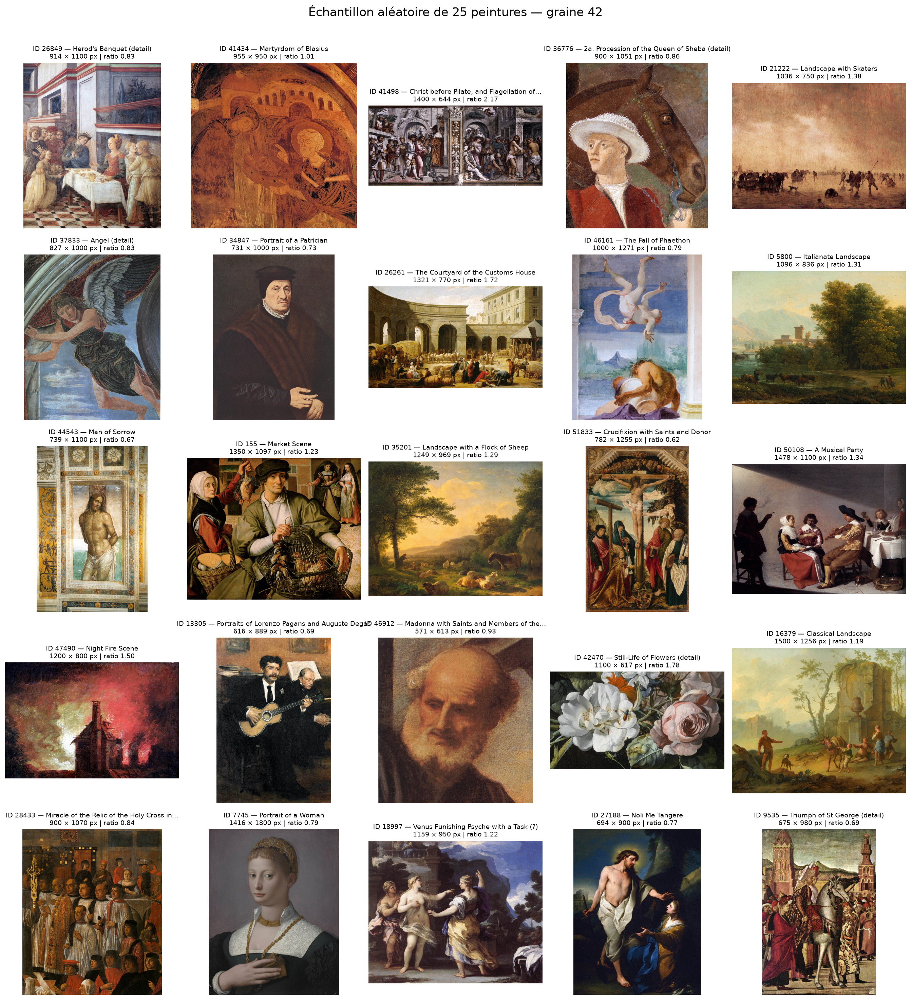

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import textwrap

# Relecture du fichier pour utiliser la liste validée à l’étape 10.
usable_images = pd.read_csv(
    PROJECT_ROOT
    / "data/interim/image_quality/usable_images.csv"
)

if usable_images.empty:
    raise ValueError("La liste des images utilisables est vide.")

sample = usable_images.sample(
    n=min(25, len(usable_images)),
    random_state=42,
).copy()

fig, axes = plt.subplots(5, 5, figsize=(18, 20))
axes = axes.ravel()

for ax in axes:
    ax.axis("off")

for ax, (_, row) in zip(axes, sample.iterrows()):
    image_path = PROJECT_ROOT / row["image_path"]

    with Image.open(image_path) as original:
        image = ImageOps.exif_transpose(original)

        # Copie d’affichage uniquement : aucun fichier n’est modifié.
        image = image.convert("RGB")
        width, height = image.size

        # Réduire la copie pour limiter la mémoire de la grille.
        image.thumbnail((600, 600))

        ax.imshow(image, aspect="equal")

    title = str(row["TITLE"])
    short_title = textwrap.shorten(
        title,
        width=45,
        placeholder="…",
    )

    ax.set_title(
        f"ID {int(row['source_record'])} — {short_title}\n"
        f"{width} × {height} px | ratio {width / height:.2f}",
        fontsize=9,
    )

fig.suptitle(
    "Échantillon aléatoire de 25 peintures — graine 42",
    fontsize=17,
)

plt.tight_layout(rect=(0, 0, 1, 0.97))

# Conserver la figure et les références de l’échantillon.
figure_dir = PROJECT_ROOT / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "sample_25_paintings.png",
    dpi=150,
    bbox_inches="tight",
)

sample.to_csv(
    PROJECT_ROOT
    / "data/interim/image_quality/visual_sample_25.csv",
    index=False,
    encoding="utf-8",
)

plt.close(fig)

display(
    IPythonImage(
        filename=str(
            figure_dir / "sample_25_paintings.png"
        )
    )
)

### Observations et incidence sur le preprocessing

L’échantillon présente des images verticales et horizontales, avec des
résolutions différentes. Il faudra produire une taille d’entrée commune
pour le GAN, tout en choisissant comment gérer les proportions :
un redimensionnement direct déforme les œuvres, tandis qu’un recadrage
peut supprimer des éléments importants.

Les sujets et compositions sont variés : portraits, paysages, natures
mortes, scènes religieuses et scènes de groupe. Les couleurs et la
luminosité diffèrent également, avec des peintures sombres, claires,
aux tons chauds ou froids. Cette diversité rend l’apprentissage plus
complexe pour un petit corpus de 1 000 images.

Plusieurs images représentent explicitement des détails d’œuvres.
Le dataset contient donc des œuvres entières et des fragments :
ce ne sont pas nécessairement des erreurs de téléchargement.
Nous conservons ces fragments pour cette première expérimentation,
en documentant cette caractéristique.

Certaines reproductions incluent des éléments décoratifs autour de
la scène peinte. Aucun retrait automatique de bordures n’est décidé
à ce stade, car ces éléments peuvent appartenir à l’œuvre.

Pour la suite, les images seront converties en RGB, adaptées à une
résolution commune, puis converties en tenseurs et normalisées.
À 64 × 64 pixels, beaucoup de petits détails seront perdus :
l’apprentissage portera surtout sur les couleurs, les formes générales
et les compositions.

## Choix de la résolution

Nous retenons une résolution de 32 × 32 pixels avec 3 canaux RGB.

Cette résolution limite les besoins en calcul et en mémoire pour une
première expérimentation pédagogique. Elle est aussi adaptée à une
architecture convolutionnelle utilisant des changements de taille
successifs par facteur 2.

La réduction entraînera une perte importante des détails. L’objectif
initial sera d’observer l’apprentissage des couleurs, des textures
et des compositions générales.

Un passage à 64 × 64 pourra être envisagé après validation du pipeline
et de l’entraînement.

In [40]:
from IPython.display import display, Image as DisplayImage

IMAGE_SIZE = 32
IMAGE_CHANNELS = 3

usable_images = pd.read_csv(
    PROJECT_ROOT
    / "data/interim/image_quality/usable_images.csv"
)


def load_rgb(image_path):
    """Charger une copie RGB avec l’orientation EXIF corrigée."""
    with Image.open(image_path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def resize_image(image, method="crop", size=IMAGE_SIZE):
    """Produire une image carrée sans modifier le fichier original."""
    target = (size, size)
    interpolation = Image.Resampling.LANCZOS

    if method == "resize":
        # Largeur et hauteur forcées : déformation possible.
        return image.resize(target, resample=interpolation)

    if method == "crop":
        # Recadrage central et redimensionnement proportionnel.
        return ImageOps.fit(
            image,
            target,
            method=interpolation,
            centering=(0.5, 0.5),
        )

    if method == "padding":
        # Œuvre entière, proportions conservées et bandes noires.
        return ImageOps.pad(
            image,
            target,
            method=interpolation,
            color=(0, 0, 0),
            centering=(0.5, 0.5),
        )

    raise ValueError(f"Méthode inconnue : {method}")

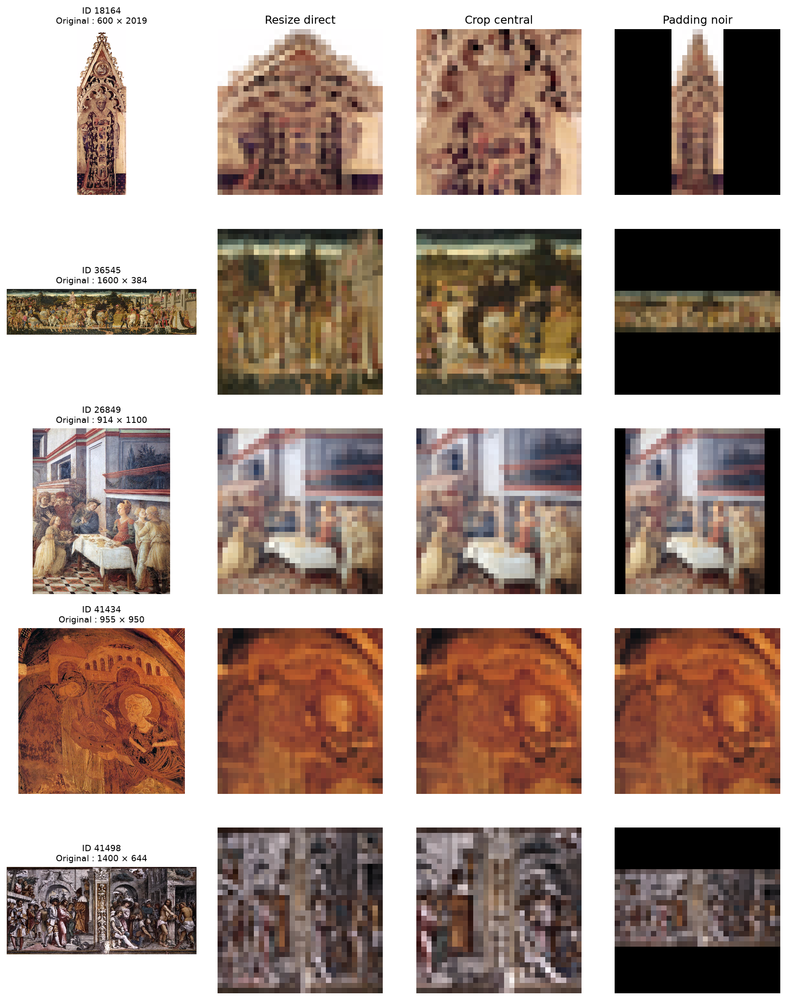

In [41]:
if usable_images.empty:
    raise ValueError("Aucune image utilisable.")

ratios = usable_images["ratio_width_height"]

extreme_indices = [
    ratios.idxmin(),
    ratios.idxmax(),
]

comparison_sample = pd.concat([
    usable_images.loc[extreme_indices],
    usable_images.sample(
        n=min(3, len(usable_images)),
        random_state=42,
    ),
]).drop_duplicates("source_record")

methods = ["resize", "crop", "padding"]
column_titles = [
    "Original",
    "Resize direct",
    "Crop central",
    "Padding noir",
]

fig, axes = plt.subplots(
    len(comparison_sample),
    4,
    figsize=(12, 3 * len(comparison_sample)),
    squeeze=False,
)

for row_number, (_, record) in enumerate(
    comparison_sample.iterrows()
):
    original = load_rgb(
        PROJECT_ROOT / record["image_path"]
    )

    images = [original] + [
        resize_image(original, method)
        for method in methods
    ]

    for column_number, image in enumerate(images):
        ax = axes[row_number, column_number]

        # Afficher les pixels 32 × 32 sans lissage supplémentaire.
        ax.imshow(image, interpolation="nearest")
        ax.axis("off")

        if row_number == 0:
            ax.set_title(column_titles[column_number])

    axes[row_number, 0].set_title(
        f"ID {int(record['source_record'])}\n"
        f"Original : {original.width} × {original.height}",
        fontsize=9,
    )

plt.tight_layout()

figure_dir = PROJECT_ROOT / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

comparison_path = figure_dir / "comparison_image_ratios.png"

fig.savefig(
    comparison_path,
    dpi=150,
    bbox_inches="tight",
)

plt.close(fig)
display(DisplayImage(filename=str(comparison_path)))

##  Traitement des ratios

Pour cette première expérimentation, nous retenons un recadrage central
suivi d’un redimensionnement à 32 × 32 pixels.

Cette méthode conserve les proportions des éléments représentés et
évite d’ajouter des bandes autour des images. Elle entraîne toutefois
une perte de contenu sur les bords, particulièrement pour les œuvres
très verticales ou très horizontales.

Le GAN apprendra donc à générer des fragments carrés de peintures,
plutôt que systématiquement des œuvres entières.

Les fichiers originaux sont conservés. Les transformations sont
appliquées en mémoire lors de la préparation des entrées du modèle.

In [42]:
import torch

RATIO_METHOD = "crop"


def image_to_tensor(image):
    """Image RGB → tenseur float32 de forme [C, H, W], dans [0, 1]."""
    pixels = np.array(image, dtype=np.uint8, copy=True)

    tensor = torch.from_numpy(pixels)
    tensor = tensor.permute(2, 0, 1).contiguous()
    tensor = tensor.to(dtype=torch.float32) / 255.0

    return tensor


def normalize_tensor(tensor):
    """Tenseur dans [0, 1] → tenseur dans [-1, 1]."""
    return (tensor - 0.5) / 0.5


def preprocess_image(image_path):
    """Pipeline complet pour une image."""
    image = load_rgb(image_path)
    image = resize_image(
        image,
        method=RATIO_METHOD,
        size=IMAGE_SIZE,
    )

    tensor = image_to_tensor(image)
    tensor = normalize_tensor(tensor)

    return tensor

In [43]:
test_sample = usable_images.sample(
    n=min(25, len(usable_images)),
    random_state=42,
)

test_batch = torch.stack([
    preprocess_image(PROJECT_ROOT / image_path)
    for image_path in test_sample["image_path"]
])

assert test_batch.shape == (
    len(test_sample),
    IMAGE_CHANNELS,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert test_batch.dtype == torch.float32
assert torch.isfinite(test_batch).all().item()
assert test_batch.min().item() >= -1.0
assert test_batch.max().item() <= 1.0

print("Forme du batch :", tuple(test_batch.shape))
print("Type :", test_batch.dtype)
print("Minimum :", test_batch.min().item())
print("Maximum :", test_batch.max().item())
print("Contrôles réussis.")

Forme du batch : (25, 3, 32, 32)
Type : torch.float32
Minimum : -1.0
Maximum : 1.0
Contrôles réussis.


## Normalisation des pixels

Après conversion en RGB et traitement des ratios, chaque image est
convertie en tenseur float32 de forme [3, 32, 32].

Les pixels sont d’abord ramenés dans [0, 1], puis le tenseur est
normalisé dans [-1, 1] par la transformation :

x_normalisé = (x - 0.5) / 0.5

Cette plage correspond à celle de la fonction tanh prévue en sortie
du générateur. Le même preprocessing sera appliqué à toutes les
images réelles utilisées pour l’entraînement.

## Pipeline de données

Le pipeline utilise un Dataset et un DataLoader PyTorch :

chemin du fichier → décodage → RGB → crop central et resize
→ tenseur → normalisation → mélange des exemples → batches.

Les images sont chargées à la demande.
La liste des fichiers provient de usable_images.csv.

La taille cible est de 32 × 32 pixels, avec 3 canaux RGB.
La taille des batches est fixée à 32.

In [44]:
from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader


class PaintingsDataset(Dataset):
    """Charger et transformer une peinture à la demande."""

    def __init__(self, project_root, preprocess):
        self.project_root = Path(project_root).resolve()
        self.preprocess = preprocess

        manifest_path = (
            self.project_root
            / "data/interim/image_quality/usable_images.csv"
        )

        manifest = pd.read_csv(manifest_path)

        if manifest.empty:
            raise ValueError("Aucune image utilisable.")

        if manifest["source_record"].duplicated().any():
            raise ValueError(
                "Identifiants source_record dupliqués dans le manifeste."
            )

        self.paths = [
            self.project_root / relative_path
            for relative_path in manifest["image_path"]
        ]

        # Vérifier les chemins sans charger les images.
        missing = [
            str(path)
            for path in self.paths
            if not path.is_file()
        ]

        if missing:
            raise FileNotFoundError(
                f"{len(missing)} fichiers absents. "
                f"Premier fichier : {missing[0]}"
            )

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return self.preprocess(self.paths[index])


dataset = PaintingsDataset(
    project_root=PROJECT_ROOT,
    preprocess=preprocess_image,
)

print("Nombre d’images dans le Dataset :", len(dataset))

Nombre d’images dans le Dataset : 1000


In [45]:
BATCH_SIZE = 32
NUM_WORKERS = 0

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(42)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=False,
    generator=shuffle_generator,
)

print("Taille des batches :", BATCH_SIZE)
print("Nombre de batches par époque :", len(train_loader))

last_batch_size = len(dataset) % BATCH_SIZE or BATCH_SIZE
print("Taille du dernier batch :", last_batch_size)

Taille des batches : 32
Nombre de batches par époque : 32
Taille du dernier batch : 8


In [46]:
images_checked = 0

for batch in train_loader:
    assert batch.ndim == 4

    assert tuple(batch.shape[1:]) == (
        IMAGE_CHANNELS,
        IMAGE_SIZE,
        IMAGE_SIZE,
    )

    assert batch.dtype == torch.float32
    assert torch.isfinite(batch).all().item()
    assert batch.min().item() >= -1.0
    assert batch.max().item() <= 1.0

    images_checked += batch.shape[0]

assert images_checked == len(dataset)

print("Images contrôlées :", images_checked)
print("Forme du dernier batch :", tuple(batch.shape))
print("Pipeline validé sur l’ensemble du corpus.")

Images contrôlées : 1000
Forme du dernier batch : (8, 3, 32, 32)
Pipeline validé sur l’ensemble du corpus.


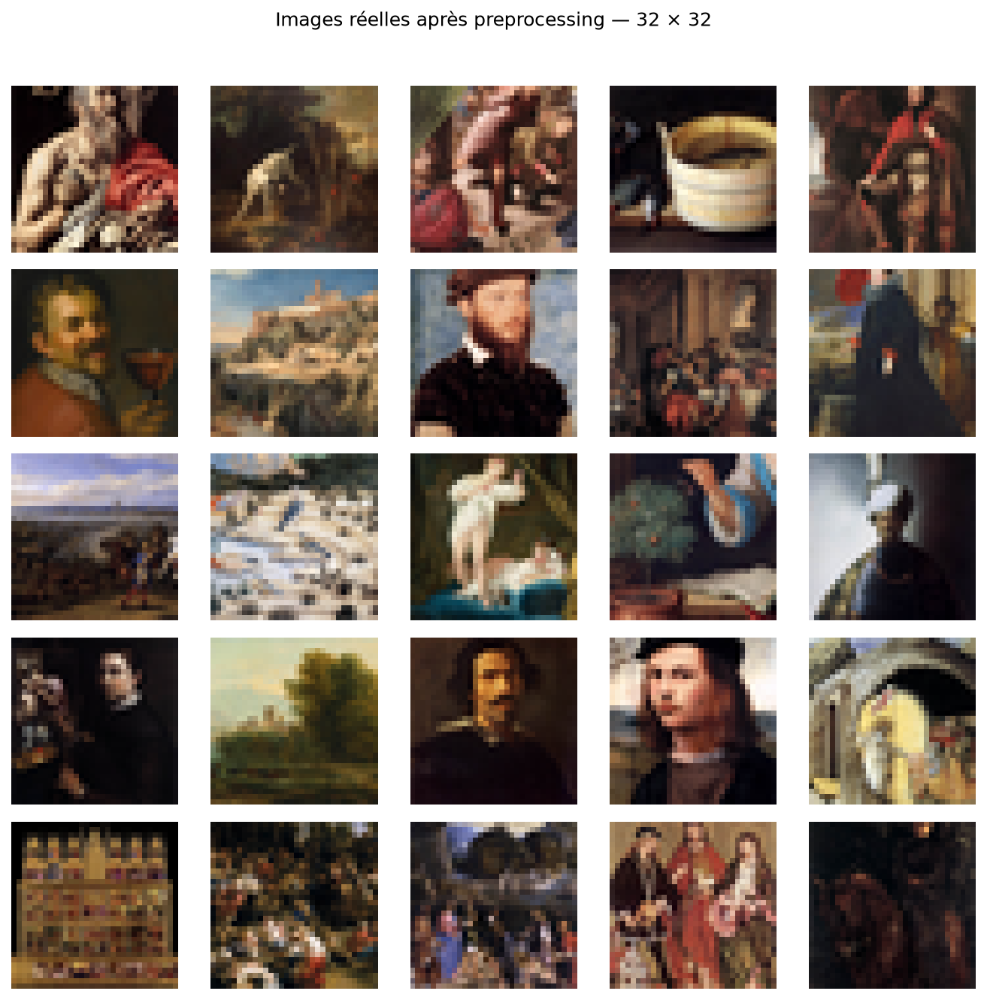

In [47]:
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

preview_batch = next(iter(train_loader))

display_images = (
    (preview_batch[:25] + 1.0) / 2.0
).clamp(0.0, 1.0)

fig, axes = plt.subplots(5, 5, figsize=(9, 9))

for ax in axes.ravel():
    ax.axis("off")

for ax, tensor in zip(axes.ravel(), display_images):
    # PyTorch : [C, H, W] ; affichage : [H, W, C].
    ax.imshow(
        tensor.permute(1, 2, 0).cpu().numpy(),
        interpolation="nearest",
    )

fig.suptitle("Images réelles après preprocessing — 32 × 32")
plt.tight_layout(rect=(0, 0, 1, 0.96))

figure_dir = PROJECT_ROOT / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

preview_path = figure_dir / "preprocessed_batch_32.png"

fig.savefig(preview_path, dpi=150, bbox_inches="tight")
plt.close(fig)

display(DisplayImage(filename=str(preview_path)))

## Choix de l’architecture

Nous retenons un DCGAN compact et non conditionnel, adapté à des
images RGB de 32 × 32 pixels.

Les convolutions exploitent la structure spatiale des images et
partagent leurs paramètres entre les positions. Ce choix constitue
une base pertinente pour apprendre des formes et des textures,
par rapport à une architecture reposant uniquement sur des couches
entièrement connectées.

Le générateur transforme un vecteur de bruit de dimension 100 en
une image, en augmentant progressivement la résolution :
4 × 4 → 8 × 8 → 16 × 16 → 32 × 32.

Le discriminateur réalise la progression inverse afin de produire
un score distinguant les images réelles des images générées.

La capacité du modèle est volontairement modérée pour tenir compte
du corpus de 1 000 images et de la durée de deux semaines du projet.
Le modèle apprend à partir des images seules, sans conditionnement
sur les artistes ou les écoles artistiques.

La sortie du générateur utilise tanh, en cohérence avec la
normalisation des images réelles dans [-1, 1].

Le Vanilla GAN est conservé comme point de comparaison théorique.
La priorité est d’obtenir un entraînement reproductible du DCGAN
et d’en analyser le comportement.

Ce choix ne garantit pas un entraînement stable ni des images
réalistes. Le faible volume de données, la diversité des peintures,
la résolution réduite et le recadrage limitent les résultats attendus.
Nous examinerons notamment la diversité des générations, une éventuelle
mémorisation et le mode collapse.

## Générateur

Le générateur transforme un vecteur latent de 100 valeurs en une
image RGB de 32 × 32 pixels.

Architecture :
- projection linéaire vers 128 × 4 × 4 valeurs ;
- reshape en 128 cartes de caractéristiques de taille 4 × 4 ;
- trois convolutions transposées : 4 → 8 → 16 → 32 pixels.

Les couches intermédiaires utilisent BatchNorm et ReLU.
La sortie utilise Tanh pour produire des pixels dans [-1, 1],
comme les images réelles après normalisation.

Dans PyTorch, les tenseurs image suivent l’ordre :
[batch, canaux, hauteur, largeur].

In [48]:
import torch
from torch import nn

LATENT_DIM = 100


class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()

        self.project = nn.Linear(latent_dim, 128 * 4 * 4)

        self.layers = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.ReLU(),

            # [128, 4, 4] → [64, 8, 8]
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # [64, 8, 8] → [32, 16, 16]
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            # [32, 16, 16] → [3, 32, 32]
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Tanh(),
        )

    def forward(self, z):
        x = self.project(z)
        x = x.reshape(z.shape[0], 128, 4, 4)
        return self.layers(x)


generator = Generator()

print(generator)
print(
    "Nombre de paramètres :",
    sum(p.numel() for p in generator.parameters()),
)

Generator(
  (project): Linear(in_features=100, out_features=2048, bias=True)
  (layers): Sequential(
    (0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ReLU()
    (5): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (9): Tanh()
  )
)
Nombre de paramètres : 372675


In [49]:
# Vérifier les deux tailles de batch rencontrées dans notre DataLoader.
generator.eval()

with torch.no_grad():
    for batch_size in (32, 8):
        z = torch.randn(batch_size, LATENT_DIM)
        fake_images = generator(z)

        assert fake_images.shape == (batch_size, 3, 32, 32)
        assert torch.isfinite(fake_images).all().item()
        assert fake_images.min().item() >= -1.0
        assert fake_images.max().item() <= 1.0

        print(
            f"Batch {batch_size} :",
            tuple(fake_images.shape),
        )

generator.train()

print("Contrôles du générateur réussis.")

Batch 32 : (32, 3, 32, 32)
Batch 8 : (8, 3, 32, 32)
Contrôles du générateur réussis.


## Discriminateur

Le discriminateur reçoit une image RGB de 32 × 32 pixels.

Trois convolutions réduisent progressivement les dimensions :
32 × 32 → 16 × 16 → 8 × 8 → 4 × 4.

Les activations LeakyReLU permettent de conserver un gradient
pour les valeurs négatives.

Après aplatissement, une couche linéaire produit un score brut
(logit) par image. Un score positif favorise la classe réelle,
un score négatif favorise la classe générée.

Aucune Sigmoid n’est ajoutée au réseau : elle sera intégrée
dans la fonction de perte BCEWithLogitsLoss.

In [50]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            # [3, 32, 32] → [32, 16, 16]
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.LeakyReLU(0.2),

            # [32, 16, 16] → [64, 8, 8]
            nn.Conv2d(32, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),

            # [64, 8, 8] → [128, 4, 4]
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 1),
        )

    def forward(self, images):
        return self.layers(images).squeeze(1)


discriminator = Discriminator()

print(discriminator)
print(
    "Nombre de paramètres :",
    sum(p.numel() for p in discriminator.parameters()),
)

Discriminator(
  (layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=2048, out_features=1, bias=True)
  )
)
Nombre de paramètres : 167841


In [51]:
generator.eval()
discriminator.eval()

with torch.no_grad():
    real_images = next(iter(train_loader))
    real_scores = discriminator(real_images)

    assert real_scores.shape == (real_images.shape[0],)
    assert torch.isfinite(real_scores).all().item()

    print("Scores des images réelles :", tuple(real_scores.shape))

    for batch_size in (32, 8):
        z = torch.randn(batch_size, LATENT_DIM)
        fake_images = generator(z)
        fake_scores = discriminator(fake_images)

        assert fake_scores.shape == (batch_size,)
        assert torch.isfinite(fake_scores).all().item()

        print(
            f"Scores générés — batch {batch_size} :",
            tuple(fake_scores.shape),
        )

generator.train()
discriminator.train()

print("Contrôles du discriminateur réussis.")

Scores des images réelles : (32,)
Scores générés — batch 32 : (32,)
Scores générés — batch 8 : (8,)
Contrôles du discriminateur réussis.


## Fonctions de perte

Nous utilisons BCEWithLogitsLoss, qui combine la Sigmoid et la
Binary Cross Entropy dans un calcul numériquement stable.

Le discriminateur produit des logits, sans Sigmoid finale.

Pour son apprentissage :
- les images réelles ont pour cible 1 ;
- les images générées ont pour cible 0 ;
- sa perte est la somme des pertes sur ces deux groupes.

Pour l’apprentissage du générateur :
- les images générées ont pour cible 1 ;
- nous utilisons la perte non saturante ;
- le générateur apprend à augmenter la probabilité que ses images
  soient considérées comme réelles par le discriminateur.

Les deux optimiseurs minimiseront leur perte respective.
Les cibles ne sont pas des annotations du catalogue : elles indiquent
simplement si l’image provient du dataset ou du générateur.

In [52]:
criterion = nn.BCEWithLogitsLoss()


def discriminator_loss(real_logits, fake_logits):
    real_loss = criterion(
        real_logits,
        torch.ones_like(real_logits),
    )

    fake_loss = criterion(
        fake_logits,
        torch.zeros_like(fake_logits),
    )

    return real_loss + fake_loss


def generator_loss(fake_logits):
    return criterion(
        fake_logits,
        torch.ones_like(fake_logits),
    )

In [53]:
import math

neutral_logits = torch.zeros(8)

loss_d = discriminator_loss(
    neutral_logits,
    neutral_logits,
)

loss_g = generator_loss(neutral_logits)

assert math.isclose(
    loss_d.item(), 2 * math.log(2), rel_tol=1e-6
)

assert math.isclose(
    loss_g.item(), math.log(2), rel_tol=1e-6
)

# Vérifier aussi le sens des pertes.
good_real = torch.full((8,), 5.0)
good_fake = torch.full((8,), -5.0)

assert (
    discriminator_loss(good_real, good_fake)
    < discriminator_loss(good_fake, good_real)
).item()

assert (
    generator_loss(good_real)
    < generator_loss(good_fake)
).item()

print(f"Perte D — logits nuls : {loss_d.item():.4f}")
print(f"Perte G — logits nuls : {loss_g.item():.4f}")
print("Contrôles des losses réussis.")

Perte D — logits nuls : 1.3863
Perte G — logits nuls : 0.6931
Contrôles des losses réussis.


In [54]:
LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999
EPOCHS = 20

# Réutiliser les valeurs déjà définies dans le notebook.
assert IMAGE_SIZE == 32
assert IMAGE_CHANNELS == 3
assert LATENT_DIM == 100
assert train_loader.batch_size == BATCH_SIZE == 32

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

generator = generator.to(device)
discriminator = discriminator.to(device)

config = {
    "image_size": IMAGE_SIZE,
    "image_channels": IMAGE_CHANNELS,
    "batch_size": BATCH_SIZE,
    "latent_dim": LATENT_DIM,
    "learning_rate_g": LEARNING_RATE,
    "learning_rate_d": LEARNING_RATE,
    "beta1": BETA1,
    "beta2": BETA2,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "architecture": "DCGAN compact non conditionnel",
    "generator_channels": [128, 64, 32, 3],
    "discriminator_channels": [32, 64, 128],
    "generator_activation": "ReLU / Tanh",
    "discriminator_activation": "LeakyReLU(0.2) / logits",
    "loss": "BCEWithLogitsLoss",
    "generator_objective": "non-saturating",
    "ratio_method": RATIO_METHOD,
    "normalization": "[-1, 1]",
    "num_workers": train_loader.num_workers,
    "drop_last": train_loader.drop_last,
    "dataset_size": len(dataset),
    "device": str(device),
}

display(
    pd.DataFrame(
        [(key, str(value)) for key, value in config.items()],
        columns=["Paramètre", "Valeur"],
    )
)

print("Appareil utilisé :", device)

,Paramètre,Valeur
0,image_size,32
1,image_channels,3
2,batch_size,32
3,latent_dim,100
4,learning_rate_g,0.0002
5,learning_rate_d,0.0002
6,beta1,0.5
7,beta2,0.999
8,epochs,20
9,optimizer,Adam


Appareil utilisé : cpu


In [55]:
optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, BETA2),
)

print("Optimiseurs du générateur et du discriminateur créés.")

Optimiseurs du générateur et du discriminateur créés.


In [56]:
import json

config_dir = PROJECT_ROOT / "reports"
config_dir.mkdir(parents=True, exist_ok=True)

config_path = config_dir / "gan_initial_config.json"

config_path.write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Configuration enregistrée :", config_path)
print("Batches par époque :", len(train_loader))
print(
    "Mises à jour prévues par réseau :",
    EPOCHS * len(train_loader),
)

Configuration enregistrée : C:\wamp64\www\ganisme\reports\gan_initial_config.json
Batches par époque : 32
Mises à jour prévues par réseau : 640


## Hyperparamètres du premier entraînement

Nous utilisons des images RGB de 32 × 32 pixels, des batches de 32
et un espace latent de dimension 100.

Chaque réseau possède son propre optimiseur Adam, avec un learning
rate de 0.0002 et les coefficients beta1 = 0.5 et beta2 = 0.999.

Le premier essai est limité à 20 époques. Cette valeur constitue
un budget d’expérimentation initial, sans garantie de convergence.
Une prolongation sera envisagée selon le temps disponible et
l’évolution des générations.

La configuration est sauvegardée dans reports/gan_initial_config.json.
Les ajustements ultérieurs seront documentés pour distinguer
les différents essais.

In [57]:
import time
from PIL import Image

run_dir = PROJECT_ROOT / "outputs/dcgan_32"
run_dir.mkdir(parents=True, exist_ok=True)

fixed_noise = torch.randn(25, LATENT_DIM, device=device)
history = []
completed_epochs = 0


def save_generated_grid(epoch):
    """Sauvegarder 25 générations avec le même bruit."""
    generator.eval()

    with torch.no_grad():
        images = generator(fixed_noise)
        images = ((images + 1) / 2).clamp(0, 1)
        images = (
            images.permute(0, 2, 3, 1)
            .cpu()
            .mul(255)
            .round()
            .to(torch.uint8)
            .numpy()
        )

    grid = Image.new("RGB", (5 * IMAGE_SIZE, 5 * IMAGE_SIZE))

    for index, pixels in enumerate(images):
        grid.paste(
            Image.fromarray(pixels),
            (
                (index % 5) * IMAGE_SIZE,
                (index // 5) * IMAGE_SIZE,
            ),
        )

    grid.save(run_dir / f"epoch_{epoch:03d}.png")
    generator.train()


# Référence avant entraînement.
save_generated_grid(0)

In [58]:
def train_gan(target_epochs):
    global completed_epochs

    generator.train()
    discriminator.train()

    for epoch in range(completed_epochs + 1, target_epochs + 1):
        start = time.perf_counter()
        total_d = 0.0
        total_g = 0.0
        images_seen = 0

        for real_images in train_loader:
            real_images = real_images.to(device)
            batch_size = real_images.shape[0]

            # 1. Générer des images à partir du bruit.
            noise = torch.randn(
                batch_size, LATENT_DIM, device=device
            )
            fake_images = generator(noise)

            # 2. Entraîner le discriminateur.
            optimizer_d.zero_grad(set_to_none=True)

            real_logits = discriminator(real_images)
            fake_logits = discriminator(fake_images.detach())

            loss_d = discriminator_loss(
                real_logits, fake_logits
            )
            loss_d.backward()
            optimizer_d.step()

            # 3. Entraîner le générateur.
            # On conserve le passage du gradient à travers D,
            # mais sans calculer de gradients pour ses paramètres.
            discriminator.requires_grad_(False)

            try:
                optimizer_g.zero_grad(set_to_none=True)

                fake_logits = discriminator(fake_images)
                loss_g = generator_loss(fake_logits)

                loss_g.backward()
                optimizer_g.step()
            finally:
                discriminator.requires_grad_(True)

            # Moyennes pondérées : le dernier batch contient 8 images.
            total_d += loss_d.item() * batch_size
            total_g += loss_g.item() * batch_size
            images_seen += batch_size

        seconds = time.perf_counter() - start

        history.append({
            "epoch": epoch,
            "loss_d": total_d / images_seen,
            "loss_g": total_g / images_seen,
            "seconds": seconds,
        })
        completed_epochs = epoch

        # 4. Sauvegarder les résultats de l’époque.
        save_generated_grid(epoch)

        pd.DataFrame(history).to_csv(
            run_dir / "losses.csv", index=False
        )

        torch.save({
            "epoch": epoch,
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_g": optimizer_g.state_dict(),
            "optimizer_d": optimizer_d.state_dict(),
            "fixed_noise": fixed_noise,
            "history": history,
            "config": dict(config, epochs=target_epochs),
        }, run_dir / "checkpoint_latest.pt")

        print(
            f"Époque {epoch}/{target_epochs} | "
            f"D : {history[-1]['loss_d']:.4f} | "
            f"G : {history[-1]['loss_g']:.4f} | "
            f"{seconds:.1f} s",
            flush=True,
        )

In [59]:
train_gan(target_epochs=1)

epoch_seconds = history[-1]["seconds"]

print(
    f"Estimation pour {EPOCHS} époques : "
    f"{epoch_seconds * EPOCHS / 60:.1f} minutes "
    "(hors coût des sauvegardes, estimation approximative)."
)

Époque 1/1 | D : 0.5322 | G : 2.1368 | 27.9 s
Estimation pour 20 époques : 9.3 minutes (hors coût des sauvegardes, estimation approximative).


In [60]:
train_gan(target_epochs=EPOCHS)

Époque 2/20 | D : 0.2203 | G : 3.6922 | 27.7 s
Époque 3/20 | D : 0.1713 | G : 4.5410 | 25.9 s
Époque 4/20 | D : 0.1014 | G : 4.7570 | 26.3 s
Époque 5/20 | D : 0.0812 | G : 5.3264 | 26.0 s
Époque 6/20 | D : 0.1819 | G : 5.1091 | 25.9 s
Époque 7/20 | D : 0.6391 | G : 3.4116 | 26.0 s
Époque 8/20 | D : 0.5176 | G : 2.8885 | 25.9 s
Époque 9/20 | D : 0.3909 | G : 3.2697 | 25.9 s
Époque 10/20 | D : 0.4162 | G : 3.6266 | 25.9 s
Époque 11/20 | D : 0.4436 | G : 3.6725 | 26.1 s
Époque 12/20 | D : 0.3443 | G : 3.5074 | 25.9 s
Époque 13/20 | D : 0.4756 | G : 3.6122 | 25.9 s
Époque 14/20 | D : 0.6371 | G : 2.8799 | 25.7 s
Époque 15/20 | D : 0.6446 | G : 2.8969 | 25.8 s
Époque 16/20 | D : 0.5049 | G : 2.7364 | 25.8 s
Époque 17/20 | D : 0.5221 | G : 3.2818 | 25.8 s
Époque 18/20 | D : 0.4798 | G : 3.1810 | 26.0 s
Époque 19/20 | D : 0.5006 | G : 3.1903 | 26.1 s
Époque 20/20 | D : 0.3715 | G : 3.2351 | 25.8 s


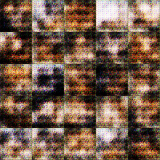

,epoch,loss_d,loss_g,seconds
15,16,0.504907,2.736450,25.763313
16,17,0.522074,3.281773,25.839922
17,18,0.479758,3.180977,25.990969
18,19,0.500564,3.190299,26.058214
19,20,0.371457,3.235069,25.845528


In [61]:
from IPython.display import display, Image as DisplayImage

display(
    DisplayImage(
        filename=str(
            run_dir / f"epoch_{completed_epochs:03d}.png"
        ),
        width=640,
    )
)

display(pd.DataFrame(history).tail())

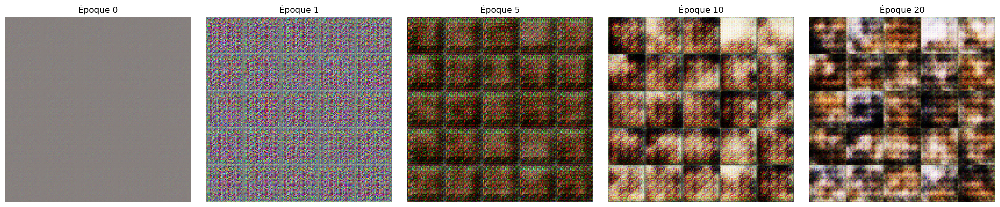

In [62]:
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as DisplayImage

epochs_to_compare = [0, 1, 5, 10, 20]

fig, axes = plt.subplots(
    1, len(epochs_to_compare),
    figsize=(20, 4),
)

for ax, epoch in zip(axes, epochs_to_compare):
    path = run_dir / f"epoch_{epoch:03d}.png"

    with Image.open(path) as image:
        ax.imshow(image, interpolation="nearest")

    ax.set_title(f"Époque {epoch}")
    ax.axis("off")

plt.tight_layout()

comparison_path = run_dir / "training_evolution.png"
fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.close(fig)

display(DisplayImage(filename=str(comparison_path)))

## Monitoring visuel de l’entraînement

Une grille de 25 images est sauvegardée après chaque époque.
L’époque 0 correspond au générateur avant entraînement.

Les mêmes vecteurs latents sont utilisés pour toutes les grilles,
ce qui permet de comparer l’évolution des générations à entrée fixe.

Nous examinons :
- la diminution éventuelle du bruit ;
- l’apparition de formes et de structures ;
- l’évolution des couleurs ;
- la diversité entre les images ;
- une éventuelle dégradation au fil des époques.

Cette analyse complète les pertes. Une amélioration des losses
ne garantit pas une amélioration de la qualité visuelle.

La progression vers des peintures plausibles n’est pas garantie :
le modèle peut stagner, régresser ou produire des images similaires.

### Interprétation du monitoring visuel

Les générations évoluent d’images presque uniformes vers du bruit
coloré, puis vers des zones de couleurs et de contrastes plus organisées.

À l’époque 20, les tons bruns, rouges et crème évoquent partiellement
les palettes du corpus. Cependant, aucun sujet ni composition picturale
n’est clairement reconnaissable. Des textures bruitées et des motifs
répétitifs restent visibles.

Les images présentent des différences entre elles, mais cette grille
ne suffit pas à exclure un mode collapse partiel ni à mesurer la
diversité du modèle.

L’entraînement modifie donc les générations, sans atteindre à ce stade
une qualité permettant de parler de peintures plausibles.
Le monitoring visuel complète les pertes et évite de confondre
fonctionnement technique et qualité des résultats.

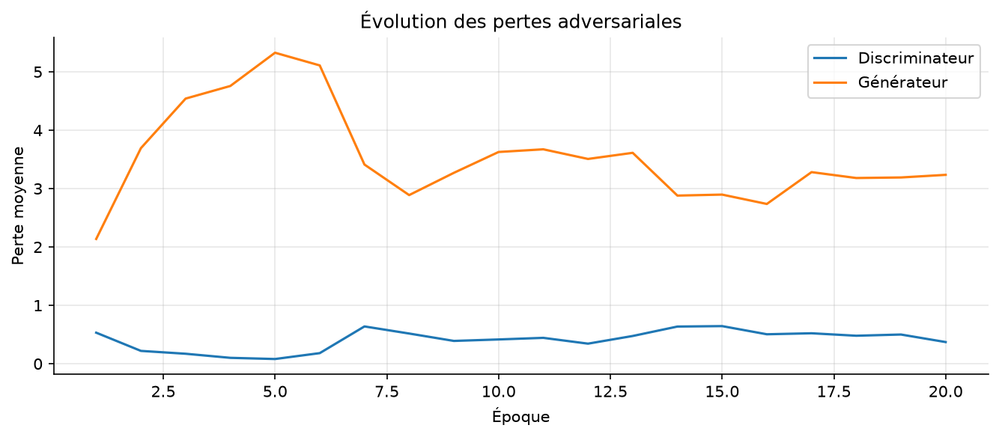

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

losses = pd.read_csv(run_dir / "losses.csv")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(losses["epoch"], losses["loss_d"], label="Discriminateur")
ax.plot(losses["epoch"], losses["loss_g"], label="Générateur")

ax.set(
    xlabel="Époque",
    ylabel="Perte moyenne",
    title="Évolution des pertes adversariales",
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

loss_path = run_dir / "training_losses.png"
fig.savefig(loss_path, dpi=150, bbox_inches="tight")
plt.close(fig)

display(DisplayImage(filename=str(loss_path)))

## Surveillance des problèmes classiques

### Mode collapse

Les générations présentent des variations de couleurs et de formes,
mais aussi des textures répétitives et une faible diversité apparente
des structures.

La grille ne montre pas 25 images strictement identiques. Elle ne permet
cependant pas d’exclure un mode collapse partiel. Une faible qualité
visuelle ne constitue pas, à elle seule, une preuve de mode collapse.

### Discriminateur dominant

Entre les époques 2 et 5, la perte du discriminateur diminue fortement,
tandis que celle du générateur augmente. Cela suggère que le discriminateur
sépare facilement les images réelles des générations pendant cette période.

Les pertes évoluent ensuite et les générations changent visuellement.
Nous ne pouvons donc pas conclure que le générateur n’apprend rien,
mais il ne produit pas encore de peintures reconnaissables.

### Générateur dominant

Les résultats ne fournissent pas d’indice clair d’un générateur dominant.
Sa perte reste élevée et la qualité visuelle demeure faible.

Une faible perte du générateur ne suffirait toutefois pas à démontrer
une bonne qualité : elle pourrait également refléter les faiblesses
du discriminateur.

### Instabilité

Les pertes oscillent, notamment autour des époques 6 et 7, mais restent
finies dans les valeurs enregistrées. Aucune divergence numérique
n’est visible dans ces moyennes.

Les oscillations sont compatibles avec la dynamique adversariale.
Elles ne démontrent ni une convergence ni une instabilité sévère.

### Bilan

Le problème principal observé est la faible qualité des générations,
avec une domination initiale du discriminateur et des motifs répétitifs.

Nous conservons ce premier essai comme référence. Les diagnostics
restent qualitatifs et devront guider des expérimentations contrôlées,
en modifiant un seul facteur à la fois.

In [64]:
import shutil

experiments_dir = PROJECT_ROOT / "outputs/experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

exp01_dir = experiments_dir / "EXP01"

# Copier une seule fois le premier entraînement.
if not exp01_dir.exists():
    shutil.copytree(
        PROJECT_ROOT / "outputs/dcgan_32",
        exp01_dir,
    )

print("Premier essai conservé dans :", exp01_dir)

Premier essai conservé dans : C:\wamp64\www\ganisme\outputs\experiments\EXP01


In [65]:
def prepare_experiment(name, batch_size=32, lr_d=0.0002):
    global generator, discriminator
    global optimizer_g, optimizer_d, train_loader
    global fixed_noise, history, completed_epochs, run_dir, config

    destination = experiments_dir / name

    if destination.exists():
        raise FileExistsError(
            f"{name} existe déjà : choisir un nouveau nom "
            "pour éviter d’écraser ses résultats."
        )

    # Même initialisation et même bruit pour les nouveaux essais.
    torch.manual_seed(42)

    generator = Generator().to(device)
    discriminator = Discriminator().to(device)

    optimizer_g = torch.optim.Adam(
        generator.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999),
    )
    optimizer_d = torch.optim.Adam(
        discriminator.parameters(),
        lr=lr_d,
        betas=(0.5, 0.999),
    )

    train_loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        drop_last=False,
        generator=torch.Generator().manual_seed(42),
    )

    fixed_noise = torch.randn(25, LATENT_DIM, device=device)
    history = []
    completed_epochs = 0
    run_dir = destination
    run_dir.mkdir(parents=True)

    config = dict(
        config,
        experiment=name,
        batch_size=batch_size,
        learning_rate_g=0.0002,
        learning_rate_d=lr_d,
        epochs=20,
        seed=42,
    )

    (run_dir / "config.json").write_text(
        json.dumps(config, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    save_generated_grid(0)

    print(name, "| batches par époque :", len(train_loader))

In [66]:
prepare_experiment(
    "EXP02",
    batch_size=32,
    lr_d=0.0001,
)

train_gan(target_epochs=20)

EXP02 | batches par époque : 32
Époque 1/20 | D : 1.1682 | G : 0.9402 | 29.5 s
Époque 2/20 | D : 0.7977 | G : 1.5598 | 26.8 s
Époque 3/20 | D : 0.7939 | G : 1.8322 | 25.8 s
Époque 4/20 | D : 0.5149 | G : 2.2304 | 26.8 s
Époque 5/20 | D : 0.3777 | G : 2.5972 | 26.4 s
Époque 6/20 | D : 0.3303 | G : 2.8387 | 26.5 s
Époque 7/20 | D : 0.3114 | G : 2.9584 | 26.6 s
Époque 8/20 | D : 0.2546 | G : 3.2643 | 26.3 s
Époque 9/20 | D : 0.1968 | G : 3.4035 | 26.3 s
Époque 10/20 | D : 0.3624 | G : 2.8990 | 26.4 s
Époque 11/20 | D : 0.8269 | G : 1.8740 | 26.7 s
Époque 12/20 | D : 0.8474 | G : 1.6323 | 27.0 s
Époque 13/20 | D : 0.9326 | G : 1.6542 | 27.0 s
Époque 14/20 | D : 0.9325 | G : 1.6259 | 26.5 s
Époque 15/20 | D : 0.8891 | G : 1.7390 | 26.8 s
Époque 16/20 | D : 0.7798 | G : 1.8190 | 26.4 s
Époque 17/20 | D : 0.6611 | G : 2.0768 | 26.5 s
Époque 18/20 | D : 0.6667 | G : 2.3787 | 27.8 s
Époque 19/20 | D : 0.5131 | G : 2.5225 | 26.3 s
Époque 20/20 | D : 0.7260 | G : 2.5071 | 26.2 s


In [67]:
prepare_experiment(
    "EXP03",
    batch_size=64,
    lr_d=0.0002,
)

train_gan(target_epochs=20)

EXP03 | batches par époque : 16
Époque 1/20 | D : 0.8817 | G : 1.4222 | 25.6 s
Époque 2/20 | D : 0.3561 | G : 2.6278 | 25.9 s
Époque 3/20 | D : 0.2817 | G : 3.4017 | 25.7 s
Époque 4/20 | D : 0.1913 | G : 3.9374 | 25.3 s
Époque 5/20 | D : 0.2159 | G : 4.2102 | 26.8 s
Époque 6/20 | D : 0.1709 | G : 4.5182 | 26.0 s
Époque 7/20 | D : 0.0901 | G : 4.5511 | 25.3 s
Époque 8/20 | D : 0.0639 | G : 4.6945 | 25.4 s
Époque 9/20 | D : 0.0844 | G : 5.1699 | 25.7 s
Époque 10/20 | D : 0.0611 | G : 5.3954 | 26.3 s
Époque 11/20 | D : 0.0472 | G : 5.1704 | 25.9 s
Époque 12/20 | D : 0.0438 | G : 5.3527 | 25.7 s
Époque 13/20 | D : 0.0618 | G : 5.4004 | 25.7 s
Époque 14/20 | D : 0.3325 | G : 4.9451 | 25.6 s
Époque 15/20 | D : 0.3183 | G : 3.8976 | 26.2 s
Époque 16/20 | D : 0.6766 | G : 3.6549 | 25.7 s
Époque 17/20 | D : 0.6512 | G : 3.1474 | 27.5 s
Époque 18/20 | D : 0.5268 | G : 3.1187 | 27.9 s
Époque 19/20 | D : 0.5184 | G : 2.9781 | 26.3 s
Époque 20/20 | D : 0.3171 | G : 3.1368 | 26.1 s


In [68]:
rows = []

settings = [
    ("EXP01", 32, 0.0002),
    ("EXP02", 32, 0.0001),
    ("EXP03", 64, 0.0002),
]

for name, batch_size, lr_d in settings:
    path = experiments_dir / name / "losses.csv"

    if not path.exists():
        continue

    table = pd.read_csv(path)
    last = table.iloc[-1]

    rows.append({
        "Expérience": name,
        "Architecture": "DCGAN 32 × 32",
        "LR G": 0.0002,
        "LR D": lr_d,
        "Batch": batch_size,
        "Époques réalisées": int(last["epoch"]),
        "Loss D finale": round(last["loss_d"], 4),
        "Loss G finale": round(last["loss_g"], 4),
        "Minutes hors sauvegardes": round(
            table["seconds"].sum() / 60, 2
        ),
        "Résultat visuel": "À compléter",
    })

experiment_results = pd.DataFrame(rows)
display(experiment_results)

experiment_results.to_csv(
    experiments_dir / "comparison.csv",
    index=False,
)

,Expérience,Architecture,LR G,LR D,Batch,Époques réalisées,Loss D finale,Loss G finale,Minutes hors sauvegardes,Résultat visuel
0,EXP01,DCGAN 32 × 32,0.0002,0.0002,32,20,0.3715,3.2351,8.71,À compléter
1,EXP02,DCGAN 32 × 32,0.0002,0.0001,32,20,0.7260,2.5071,8.91,À compléter
2,EXP03,DCGAN 32 × 32,0.0002,0.0002,64,20,0.3171,3.1368,8.68,À compléter


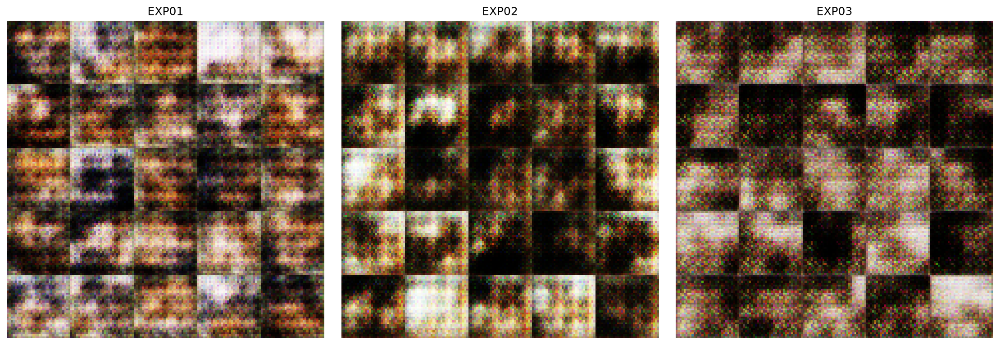

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, name in zip(axes, ["EXP01", "EXP02", "EXP03"]):
    path = experiments_dir / name / "epoch_020.png"

    if path.exists():
        with Image.open(path) as image:
            ax.imshow(image, interpolation="nearest")
    else:
        ax.text(
            0.5, 0.5, "Expérience non terminée",
            ha="center", va="center",
        )

    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()

comparison_path = experiments_dir / "comparison_final.png"
fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.close(fig)

display(DisplayImage(filename=str(comparison_path)))

## Expérimentations

Trois expériences étudient deux facteurs :
le learning rate du discriminateur et la taille des batches.

EXP01 constitue le premier essai.
EXP02 réduit uniquement le learning rate du discriminateur.
EXP03 augmente uniquement le batch par rapport à EXP01.

Chaque entraînement repart de réseaux et d’optimiseurs réinitialisés.
Le corpus, le preprocessing, l’architecture et le nombre d’époques
restent identiques.

Limites du protocole :
- EXP01 n’a pas été initialisée avec une graine explicitement fixée ;
- chaque configuration n’est exécutée qu’une fois ;
- à nombre d’époques identique, EXP03 effectue moins de mises à jour ;
- les pertes finales ne suffisent pas à sélectionner le meilleur modèle.

Les conclusions seront donc exploratoires. Nous comparerons
les structures visibles, le bruit, les motifs répétitifs et la
diversité, en complément des pertes et du temps de calcul.

### Bilan des expériences

Les trois configurations produisent des textures colorées et des
zones contrastées, mais aucune ne génère de peintures reconnaissables
après 20 époques.

EXP02, avec un learning rate du discriminateur réduit, présente
une perte finale du générateur plus faible et des zones de couleurs
plus continues. Cela suggère une modification de la dynamique
adversariale, sans démontrer une amélioration du réalisme.

EXP03, avec un batch de 64, ne présente pas de gain visuel évident
ni d’accélération notable sur CPU. À 20 époques, cette configuration
effectue 320 mises à jour par réseau, contre 640 pour les autres essais.

Les conclusions restent exploratoires : une seule exécution est
disponible par configuration, et EXP01 utilise une initialisation
différente. Les différences observées ne peuvent donc pas être
attribuées uniquement aux hyperparamètres modifiés.

Les pertes finales ne permettent pas de sélectionner un meilleur
modèle. Le bruit, les motifs répétitifs et l’absence de sujets
reconnaissables restent les principales limites communes.

In [70]:
visual_results = {
    "EXP01": "Textures variées, bruit et motifs répétitifs",
    "EXP02": "Zones plus continues, sans gain de réalisme démontré",
    "EXP03": "Texture granuleuse, aucun gain visuel évident",
}

experiment_results["Résultat visuel"] = (
    experiment_results["Expérience"].map(visual_results)
)

experiment_results.to_csv(
    experiments_dir / "comparison.csv",
    index=False,
)

display(experiment_results)

,Expérience,Architecture,LR G,LR D,Batch,Époques réalisées,Loss D finale,Loss G finale,Minutes hors sauvegardes,Résultat visuel
0,EXP01,DCGAN 32 × 32,0.0002,0.0002,32,20,0.3715,3.2351,8.71,"Textures variées, bruit et motifs répétitifs"
1,EXP02,DCGAN 32 × 32,0.0002,0.0001,32,20,0.7260,2.5071,8.91,"Zones plus continues, sans gain de réalisme dé..."
2,EXP03,DCGAN 32 × 32,0.0002,0.0002,64,20,0.3171,3.1368,8.68,"Texture granuleuse, aucun gain visuel évident"


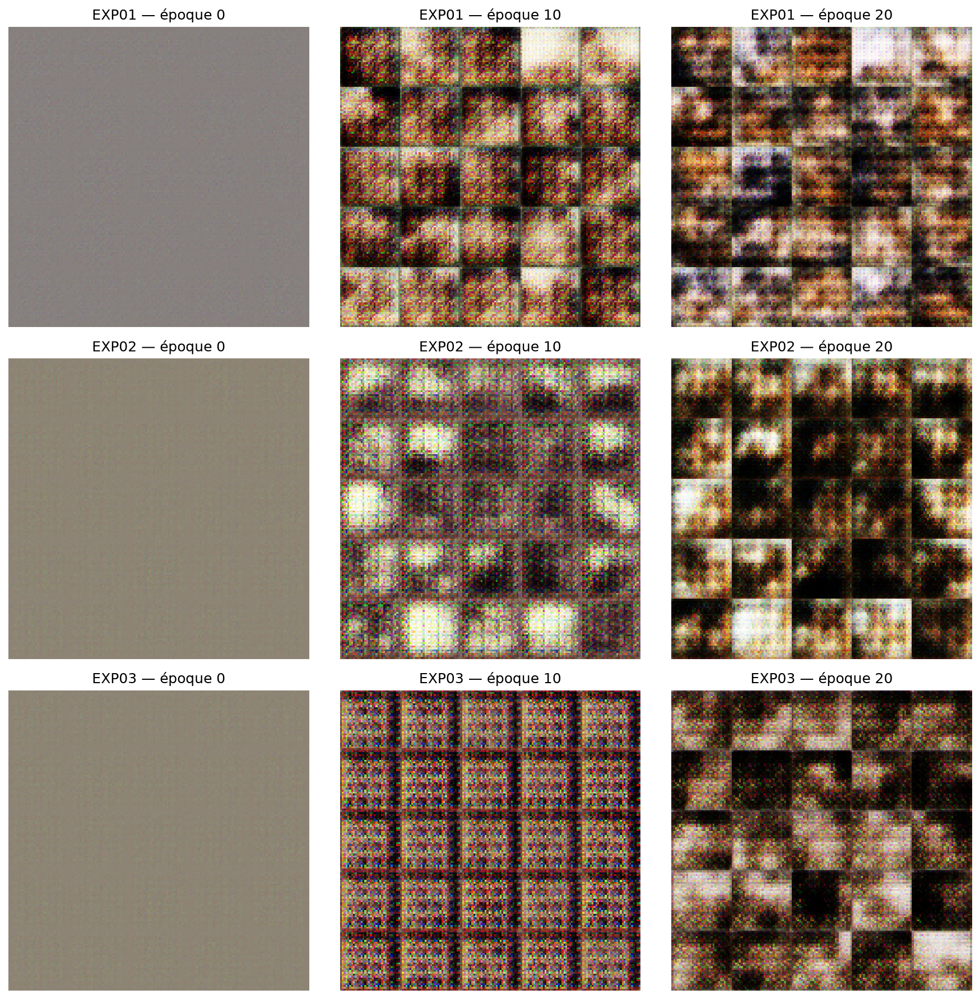

In [71]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, name in enumerate(["EXP01", "EXP02", "EXP03"]):
    for column, epoch in enumerate([0, 10, 20]):
        path = (
            experiments_dir / name / f"epoch_{epoch:03d}.png"
        )

        with Image.open(path) as image:
            axes[row, column].imshow(
                image, interpolation="nearest"
            )

        axes[row, column].set_title(
            f"{name} — époque {epoch}"
        )
        axes[row, column].axis("off")

plt.tight_layout()

evaluation_path = experiments_dir / "qualitative_evaluation.png"
fig.savefig(evaluation_path, dpi=150, bbox_inches="tight")
plt.close(fig)

display(DisplayImage(filename=str(evaluation_path)))

## Évaluation qualitative

Nous comparons les générations au début, au milieu et à la fin
des trois entraînements.

Les critères observés sont :
- apparition de structures et de compositions ;
- cohérence des couleurs ;
- présence de bruit et de motifs répétitifs ;
- diversité entre les générations ;
- ressemblance générale avec les images réelles prétraitées.

Les grilles finales montrent des zones colorées et contrastées,
mais aucun sujet clairement reconnaissable. Les générations restent
bruitées et présentent des motifs répétitifs.

EXP02 présente des zones plus continues, sans amélioration nette
du réalisme démontrée. Aucun modèle ne peut être considéré comme
satisfaisant visuellement à ce stade.

Cette évaluation est qualitative et subjective. Elle porte sur
25 générations par grille et ne suffit pas à exclure un mode
collapse partiel ou une mémorisation du corpus.

In [72]:
%pip install torchmetrics torch-fidelity

   ---------------------------------------- 0.0/983.4 kB ? eta -:--:--
   --------------------------------------- 983.4/983.4 kB 11.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 24.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [73]:
from torchmetrics.image.fid import FrechetInceptionDistance

N_EVAL = 1000
EVAL_BATCH_SIZE = 32

evaluation_loader = DataLoader(
    dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False,
    reset_real_features=False,
).to(device)

# Meilleure précision pour les statistiques et le calcul du FID.
fid_metric.set_dtype(torch.float64)


def to_uint8(images):
    """Tenseurs [-1, 1] → pixels uint8 [0, 255] pour Inception."""
    return (
        ((images + 1) / 2)
        .clamp(0, 1)
        .mul(255)
        .round()
        .to(torch.uint8)
    )


# Petit tableau de bruit, réutilisé pour les trois modèles.
evaluation_noise = torch.randn(
    N_EVAL,
    LATENT_DIM,
    generator=torch.Generator().manual_seed(123),
)

print("Préparation terminée.")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\aurel/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100.0%


Préparation terminée.


In [74]:
assert len(dataset) == N_EVAL

with torch.no_grad():
    for index, real_images in enumerate(evaluation_loader, 1):
        fid_metric.update(
            to_uint8(real_images.to(device)),
            real=True,
        )

        if index % 8 == 0:
            print(
                f"Images réelles : batch "
                f"{index}/{len(evaluation_loader)}",
                flush=True,
            )

print("Statistiques des 1 000 images réelles calculées.")

Images réelles : batch 8/32
Images réelles : batch 16/32
Images réelles : batch 24/32
Images réelles : batch 32/32
Statistiques des 1 000 images réelles calculées.


In [75]:
fid_results = []

for name in ["EXP01", "EXP02", "EXP03"]:
    print(f"\nÉvaluation de {name}", flush=True)

    checkpoint = torch.load(
        experiments_dir / name / "checkpoint_latest.pt",
        map_location="cpu",
        weights_only=True,
    )

    assert checkpoint["epoch"] == 20

    model = Generator().to(device)
    model.load_state_dict(checkpoint["generator"])
    model.eval()

    # Effacer les statistiques générées du modèle précédent.
    # Les statistiques réelles sont conservées.
    fid_metric.reset()

    with torch.no_grad():
        for start in range(0, N_EVAL, EVAL_BATCH_SIZE):
            noise = evaluation_noise[
                start:start + EVAL_BATCH_SIZE
            ].to(device)

            generated = model(noise)

            fid_metric.update(
                to_uint8(generated),
                real=False,
            )

            if start % (8 * EVAL_BATCH_SIZE) == 0:
                print(
                    f"{name} : "
                    f"{min(start + EVAL_BATCH_SIZE, N_EVAL)}"
                    f"/{N_EVAL} images",
                    flush=True,
                )

    score = fid_metric.compute().item()

    fid_results.append({
        "Expérience": name,
        "Époque": checkpoint["epoch"],
        "Images réelles": N_EVAL,
        "Images générées": N_EVAL,
        "FID": score,
    })

    # Sauvegarde progressive des scores déjà calculés.
    pd.DataFrame(fid_results).to_csv(
        experiments_dir / "fid_results.csv",
        index=False,
    )

    print(f"{name} — FID : {score:.2f}", flush=True)

    del model, checkpoint

fid_table = pd.DataFrame(fid_results)
display(fid_table.sort_values("FID"))


Évaluation de EXP01
EXP01 : 32/1000 images
EXP01 : 288/1000 images
EXP01 : 544/1000 images
EXP01 : 800/1000 images
EXP01 — FID : 281.21

Évaluation de EXP02
EXP02 : 32/1000 images
EXP02 : 288/1000 images
EXP02 : 544/1000 images
EXP02 : 800/1000 images
EXP02 — FID : 292.27

Évaluation de EXP03
EXP03 : 32/1000 images
EXP03 : 288/1000 images
EXP03 : 544/1000 images
EXP03 : 800/1000 images
EXP03 — FID : 266.87


,Expérience,Époque,Images réelles,Images générées,FID
2,EXP03,20,1000,1000,266.868261
0,EXP01,20,1000,1000,281.208994
1,EXP02,20,1000,1000,292.272040


## Évaluation quantitative

Nous calculons le FID avec les caractéristiques Inception de
dimension 2048, en utilisant TorchMetrics et torch-fidelity.

Chaque modèle est évalué à l’époque 20 sur 1 000 générations.
Les trois modèles reçoivent les mêmes vecteurs latents.
La référence contient les 1 000 images réelles après preprocessing.

Un FID plus faible indique une plus grande proximité entre
les distributions de caractéristiques, selon ce protocole.

Limites :
- estimation fondée sur un nombre limité d’images ;
- caractéristiques issues d’un réseau entraîné sur ImageNet ;
- images originales de seulement 32 × 32 pixels ;
- référence constituée des images d’entraînement ;
- absence de mesure directe de la mémorisation ou de la qualité artistique.

Le FID complète l’évaluation visuelle. Une différence faible entre
les modèles ne permettra pas d’affirmer leur supériorité sans
évaluations répétées.

Les résultats sont enregistrés dans
outputs/experiments/fid_results.csv.

### Bilan de l’évaluation qualitative et quantitative

À l’époque 20, EXP03 obtient le FID le plus faible : 266,87,
contre 281,21 pour EXP01 et 292,27 pour EXP02.

EXP03 est donc la configuration la mieux classée selon le FID
dans notre protocole. Cela ne démontre pas une supériorité générale
du batch de 64 : chaque configuration n’a été entraînée qu’une fois,
et les essais ne comportent pas tous le même nombre de mises à jour.

L’analyse visuelle montre une évolution des couleurs et des contrastes,
mais les trois modèles restent bruités et ne produisent pas de sujets
reconnaissables. Le meilleur FID ne correspond donc pas ici à une
qualité visuelle satisfaisante.

EXP02 possède la loss finale du générateur la plus faible, mais le
FID le plus élevé. La loss adversariale ne constitue donc pas une
mesure suffisante de la qualité des générations.

Ces scores sont exploratoires : ils reposent sur 1 000 images réelles
d’entraînement et 1 000 générations par modèle, à une résolution
de 32 × 32 pixels. Ils ne mesurent ni la généralisation sur un corpus
indépendant ni directement la mémorisation.

Nous retenons EXP03 comme référence pour la suite sur le critère FID,
tout en conservant les résultats des trois essais et leurs limites.

In [76]:
import json
import torch

selected_experiment = "EXP03"

checkpoint_path = (
    experiments_dir
    / selected_experiment
    / "checkpoint_latest.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["epoch"] == 20

final_dir = PROJECT_ROOT / "models/final"
final_dir.mkdir(parents=True, exist_ok=True)

# Export destiné à la génération d’images.
torch.save(
    checkpoint["generator"],
    final_dir / "generator.pt",
)

selection = {
    "experiment": selected_experiment,
    "epoch": checkpoint["epoch"],
    "fid": 266.868261,
    "selection_criterion": "Lowest FID among evaluated checkpoints",
    "config": checkpoint["config"],
}

(final_dir / "selection.json").write_text(
    json.dumps(selection, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Modèle sélectionné : EXP03 — époque 20")
print("Fichiers enregistrés dans :", final_dir)

Modèle sélectionné : EXP03 — époque 20
Fichiers enregistrés dans : C:\wamp64\www\ganisme\models\final


In [77]:
final_generator = Generator().to(device)

final_generator.load_state_dict(
    torch.load(
        final_dir / "generator.pt",
        map_location=device,
        weights_only=True,
    )
)

final_generator.eval()

with torch.no_grad():
    test_output = final_generator(
        torch.randn(8, LATENT_DIM, device=device)
    )

assert test_output.shape == (8, 3, 32, 32)
assert torch.isfinite(test_output).all().item()
assert test_output.min().item() >= -1.0
assert test_output.max().item() <= 1.0

print("Chargement du générateur final validé.")

Chargement du générateur final validé.


## Sélection du checkpoint final

Nous retenons EXP03 à l’époque 20, qui obtient le FID le plus faible
parmi les trois checkpoints évalués : 266,87.

Cette sélection repose sur une comparaison à protocole identique.
Elle ne signifie pas que le modèle produit des peintures réalistes :
la qualité visuelle reste faible.

Seuls les poids de la dernière époque de chaque expérience ont été
conservés. Les grilles intermédiaires permettent une analyse visuelle,
mais ne permettent pas de reconstruire les checkpoints correspondants.

EXP03 à l’époque 20 est donc le meilleur checkpoint parmi ceux évalués,
et non le meilleur checkpoint démontré sur l’ensemble des époques.

Les poids du générateur sont exportés dans models/final/generator.pt.
La configuration et la justification de sélection sont enregistrées
dans models/final/selection.json.